# Tugas Besar 2 IF3170 Inteligensi Artifisial

**Kelompok G14 – LalapKaoBole**

| NIM | Nama |
| --- | --- |
| 13524037 | Nicholas Wise Saragih Sumbayak |
| 13524062 | Nathan E C Marpaung |
| 13524065 | Kurt Mikhael Purba |
| 13524089 | Aurelia Jennifer Gunawan |
| 13524131 | Amanda Aurellia Salsabila |

## Pendahuluan

Tugas besar ini memprediksi apakah pemesanan kamar hotel akan dibatalkan. Ada lima algoritma yang dibandingkan, yaitu DTL, SVM, regresi logistik, Naive Bayes, dan KNN. Metrik utamanya F1 makro, sama dengan metrik yang dipakai di Kaggle.

## Impor dan konfigurasi <a id="inisialisasi"></a>

Jalankan sel secara berurutan dari atas dengan kernel `scikit-learn==1.7.1` (lihat `README.md`). Notebook cukup dijalankan di CPU dan semua hasilnya disimpan ke `output/`.

Urutan notebook: eksplorasi data, pembagian data, rekayasa fitur, pelatihan dan perbandingan tiap algoritma, lalu pembuatan submisi.

In [1]:
import pickle
import random
import sys
import time
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Video, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency
from sklearn import __version__ as sklearn_version
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score, f1_score,
    log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

if sklearn_version != '1.7.1':
    raise RuntimeError(
        f'Kernel memakai scikit-learn {sklearn_version}; diperlukan versi 1.7.1. '
        'Ikuti pemasangan di README.md, lalu pilih ulang kernel.'
    )

_NOTEBOOK_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src' / 'models' / 'svm').is_dir()
)
if str(_NOTEBOOK_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(_NOTEBOOK_ROOT / 'src'))

from models import (
    KNNClassifier, LogisticRegressionClassifier, NaiveBayesClassifier, SVM,
    TreeAugmentedNaiveBayes, classification_cost, cost_sensitive_threshold,
    predict_cost_sensitive,
)
from models.booking_features import build_blocks, raw_groups
from models.c45 import C45DecisionTree
from models.c45.visualization import plot_tree as c45_plot_tree
from models.logreg.visualization import save_logreg_training_video
from models.naive_bayes.visualization import plot_naive_bayes_graph, plot_tan_structure
from models.svm.visualization import plot_svm_boundary

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = _NOTEBOOK_ROOT
DATA_DIR = ROOT / 'data'
OUTPUT_DIR = ROOT / 'output'

print(f'Root path: {ROOT}')
print(f'Data directory: {DATA_DIR}')
print(f'Output directory: {OUTPUT_DIR}')

Root path: /home/nicholaswisee/Code/projects/IF3170_G14_LalapKaoBole
Data directory: /home/nicholaswisee/Code/projects/IF3170_G14_LalapKaoBole/data
Output directory: /home/nicholaswisee/Code/projects/IF3170_G14_LalapKaoBole/output


## Load Data

Label `is_canceled` hanya ada di `train.csv`. Kolom `id` dipakai untuk menyusun file submisi dan tidak dimasukkan ke model.

In [3]:
train_file = DATA_DIR / "train.csv"
test_file = DATA_DIR / "test.csv"
train_df = pd.read_csv(train_file, dtype={'id': str})
test_df = pd.read_csv(test_file, dtype={'id': str})

## Exploratory Data Analysis <a id="eda"></a>

Bagian ini melihat distribusi target, nilai kosong, dan hubungan antarfitur pada data latih.

### 1. Gambaran Umum

In [4]:
print("Dataset Overview:")
train_df.info()
train_df.describe(include='all')

Dataset Overview:
<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returning_guest        27373 non-null  int64  
 14 

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,27373,26564.000000,24338.000000,27373.000000,27373.000000,25613,26291.000000,26371,26250.000000,27373.000000,27373.000000,27373.000000,27373,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
unique,27373,NaN,NaN,NaN,NaN,4,NaN,7,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN
top,57152f82,NaN,NaN,NaN,NaN,Breakfast,NaN,Type B,NaN,NaN,NaN,NaN,Online Travel Agent,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,19654,NaN,20447,NaN,NaN,NaN,NaN,17511,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1.845242,0.117388,0.814854,2.206517,NaN,0.030200,NaN,85.379429,2023.820115,7.399664,15.537537,NaN,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,NaN,0.517974,0.425761,0.875146,1.421603,NaN,0.171142,NaN,85.969638,0.384099,3.074788,8.773321,NaN,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,NaN,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,NaN,0.000000,2023.000000,1.000000,1.000000,NaN,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,NaN,2.000000,0.000000,0.000000,1.000000,NaN,0.000000,NaN,17.000000,2024.000000,5.000000,8.000000,NaN,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,NaN,2.000000,0.000000,1.000000,2.000000,NaN,0.000000,NaN,58.000000,2024.000000,8.000000,16.000000,NaN,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,NaN,2.000000,0.000000,2.000000,3.000000,NaN,0.000000,NaN,126.000000,2024.000000,10.000000,23.000000,NaN,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000


#### Insight
- Data latih berisi 27.373 booking dengan 17 fitur, yaitu 14 fitur numerik dan 3 fitur kategorikal. Kolom `id` tidak dipakai karena hanya berisi kode unik.
- Skala fitur sangat berbeda. `nightly_rate_idr` bernilai jutaan, sedangkan kebanyakan fitur lain di bawah 20. KNN, SVM, dan regresi logistik butuh scaling sebelum dilatih.

### 2. Distribusi Target

In [5]:
target_counts = train_df['is_canceled'].value_counts()
print("Target Variable Distribution:")
print(target_counts)

Target Variable Distribution:
is_canceled
0    18404
1     8969
Name: count, dtype: int64


#### Insight
- Sekitar 67% booking tidak dibatalkan dan 33% dibatalkan.
- Model yang selalu menebak "tidak batal" sudah mendapat accuracy 67%. Karena itu, evaluasi memakai metrik lain seperti F1 dan ROC AUC.

### 3. Missing Values

In [6]:
missing_val_per_col = {col: train_df[col].isnull().sum() for col in train_df.columns}
for col, missing_count in missing_val_per_col.items():
    if missing_count > 0:
        print(f"Column '{col}' has {missing_count} missing values.")

Column 'num_adults' has 809 missing values.
Column 'num_children' has 3035 missing values.
Column 'meal_package' has 1760 missing values.
Column 'needs_parking' has 1082 missing values.
Column 'room_category' has 1002 missing values.
Column 'days_before_arrival' has 1123 missing values.
Column 'nightly_rate_idr' has 2038 missing values.
Column 'special_requests' has 2500 missing values.


#### Insight
- Ada delapan kolom yang memiliki nilai kosong. Paling banyak di `num_children` (11%), sedangkan kolom lain di bawah 10%.
- Sekitar 39% baris punya minimal satu nilai kosong, jadi menghapus baris akan membuang terlalu banyak data. Nilai kosong diisi median untuk fitur numerik dan modus untuk fitur kategorikal.

### 4. Data duplikat dan tidak valid

In [7]:
duplicate_rows = train_df[train_df.duplicated()]
print(f"Number of duplicate rows in the training dataset: {len(duplicate_rows)}")

Number of duplicate rows in the training dataset: 0


In [8]:
unused_features = ['id', 'is_canceled']

#### Insight
- Tidak ada baris duplikat. Namun, kalau `id` diabaikan, ada 64 baris yang isinya sama persis dengan baris lain. Baris seperti ini tidak boleh terpisah ke data latih dan validasi sekaligus.
- Tarif 0 pada 413 booking bukan kesalahan data karena sebagian besar berasal dari kanal Complimentary.

### 5. Fitur numerik

In [9]:
# Keluarkan ID dan target dari daftar fitur numerik.
numeric_features = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_features = [col for col in numeric_features if col not in unused_features]
print(f"Numeric features: {numeric_features}")


Numeric features: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']



Feature: num_adults
count    26564.000000
mean         1.845242
std          0.517974
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max          4.000000
Name: num_adults, dtype: float64


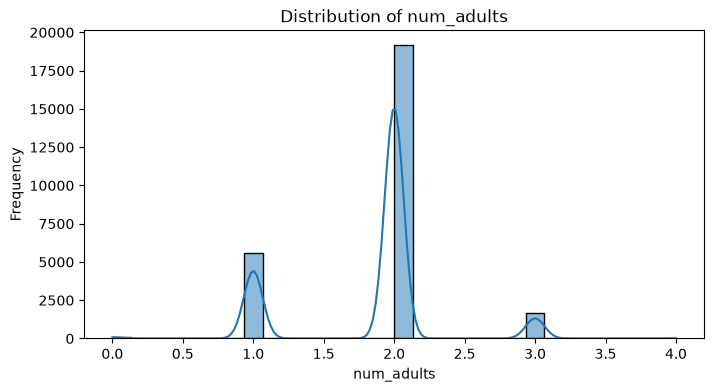


Feature: num_children
count    24338.000000
mean         0.117388
std          0.425761
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         10.000000
Name: num_children, dtype: float64


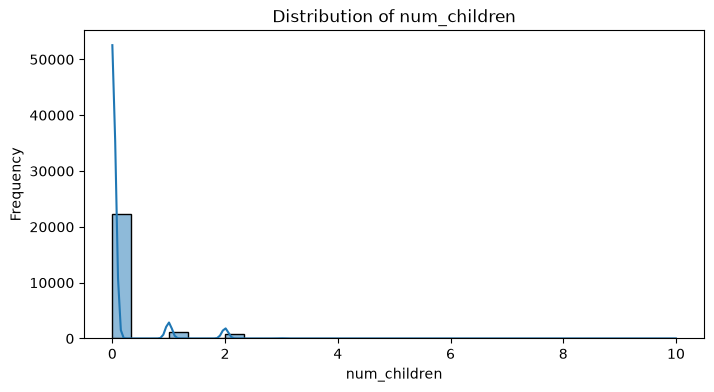


Feature: weekend_nights
count    27373.000000
mean         0.814854
std          0.875146
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          7.000000
Name: weekend_nights, dtype: float64


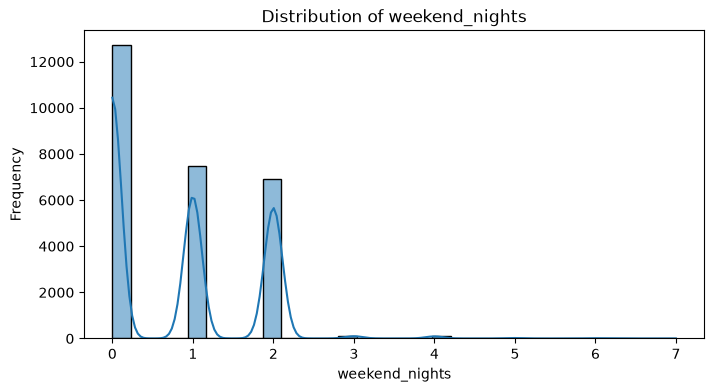


Feature: weekday_nights
count    27373.000000
mean         2.206517
std          1.421603
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         17.000000
Name: weekday_nights, dtype: float64


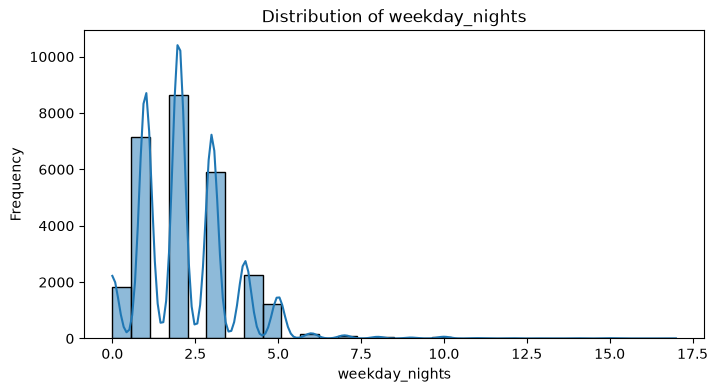


Feature: needs_parking
count    26291.000000
mean         0.030200
std          0.171142
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: needs_parking, dtype: float64


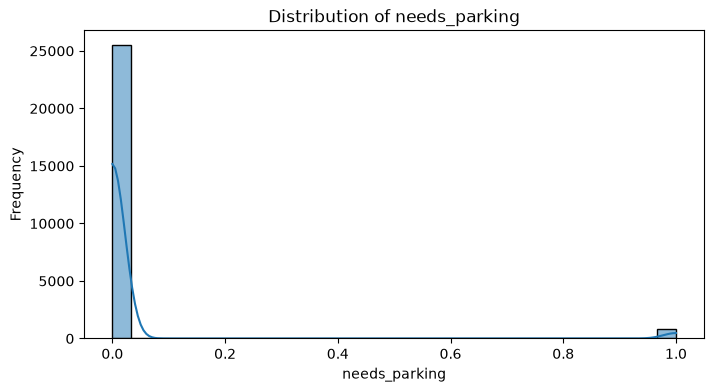


Feature: days_before_arrival
count    26250.000000
mean        85.379429
std         85.969638
min          0.000000
25%         17.000000
50%         58.000000
75%        126.000000
max        448.000000
Name: days_before_arrival, dtype: float64


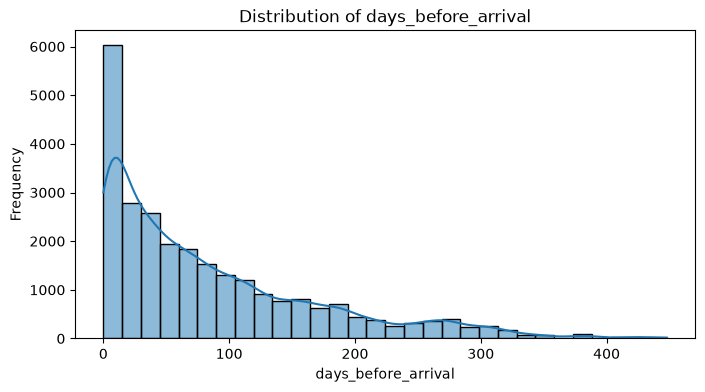


Feature: arrival_year
count    27373.000000
mean      2023.820115
std          0.384099
min       2023.000000
25%       2024.000000
50%       2024.000000
75%       2024.000000
max       2024.000000
Name: arrival_year, dtype: float64


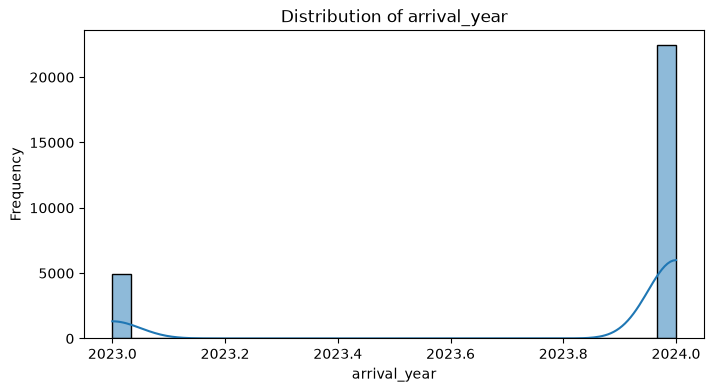


Feature: arrival_month
count    27373.000000
mean         7.399664
std          3.074788
min          1.000000
25%          5.000000
50%          8.000000
75%         10.000000
max         12.000000
Name: arrival_month, dtype: float64


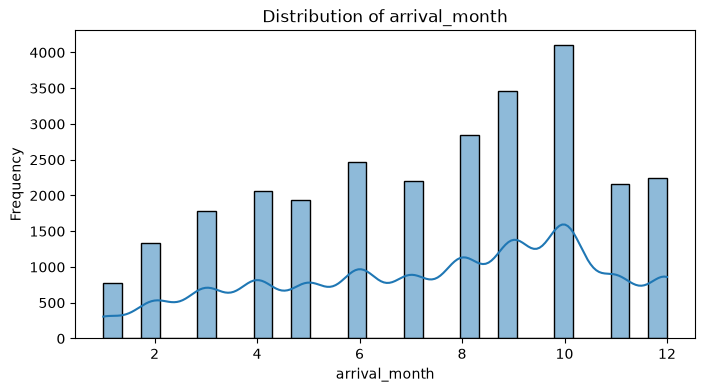


Feature: arrival_day
count    27373.000000
mean        15.537537
std          8.773321
min          1.000000
25%          8.000000
50%         16.000000
75%         23.000000
max         31.000000
Name: arrival_day, dtype: float64


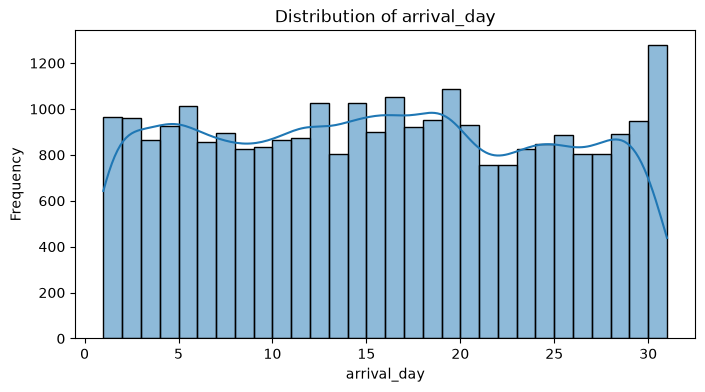


Feature: is_returning_guest
count    27373.000000
mean         0.025171
std          0.156646
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: is_returning_guest, dtype: float64


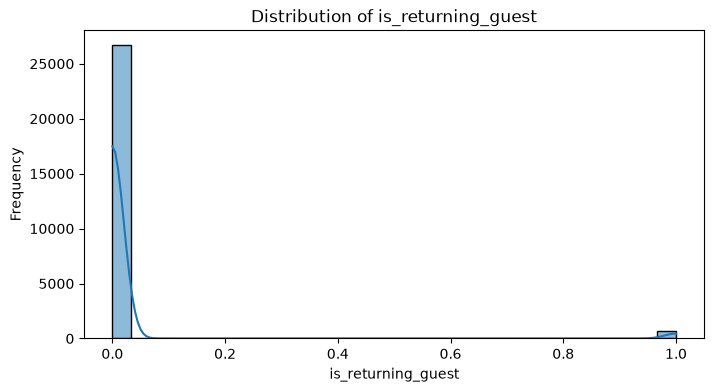


Feature: prior_cancellations
count    27373.000000
mean         0.021883
std          0.356353
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         13.000000
Name: prior_cancellations, dtype: float64


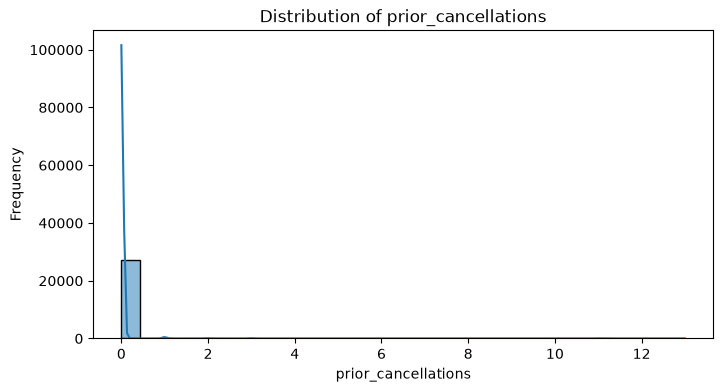


Feature: prior_completed_bookings
count    27373.000000
mean         0.144887
std          1.693652
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         58.000000
Name: prior_completed_bookings, dtype: float64


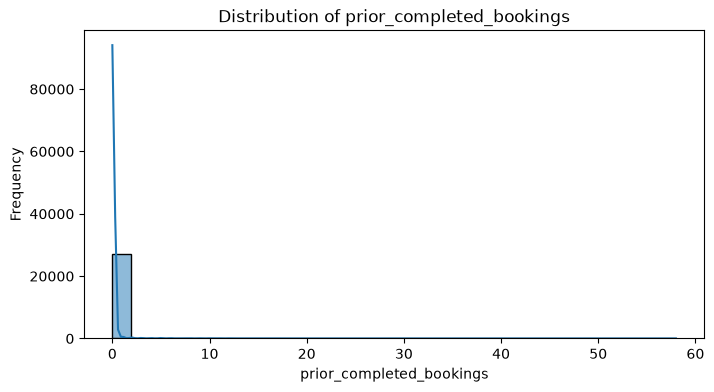


Feature: nightly_rate_idr
count    2.533500e+04
mean     1.716980e+06
std      5.879368e+05
min      0.000000e+00
25%      1.338000e+06
50%      1.644000e+06
75%      2.019000e+06
max      9.165000e+06
Name: nightly_rate_idr, dtype: float64


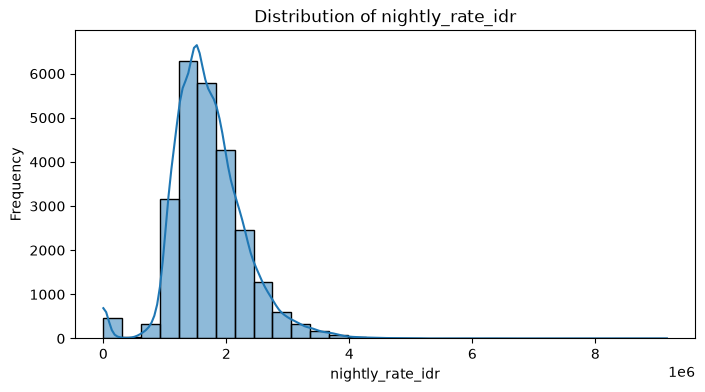


Feature: special_requests
count    24873.000000
mean         0.666948
std          0.798363
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          5.000000
Name: special_requests, dtype: float64


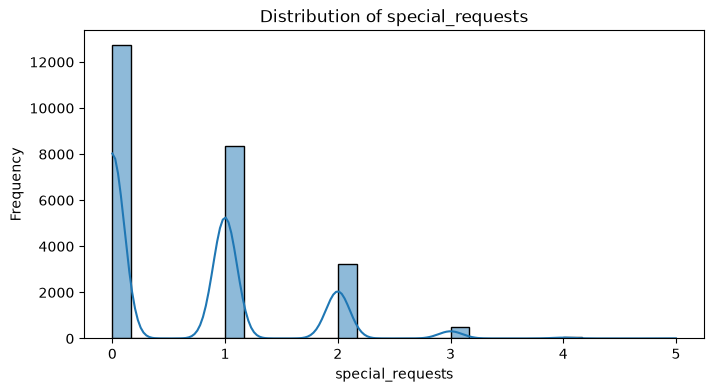

In [10]:
# Statistik deskriptif untuk fitur numerik dan histogram distribusi
for feature in numeric_features:
    print(f"\nFeature: {feature}")
    print(train_df[feature].describe())
    plt.figure(figsize=(8, 4))
    sns.histplot(train_df[feature], kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

#### Insight
- Beberapa fitur hampir selalu bernilai 0, yaitu `needs_parking`, `is_returning_guest`, `prior_cancellations`, dan `prior_completed_bookings`. Nilai selain 0 hanya muncul pada sebagian kecil booking.
- `days_before_arrival` miring ke kanan. Kebanyakan booking dibuat paling lama sekitar 4 bulan sebelum kedatangan, tetapi ada yang sampai 448 hari.

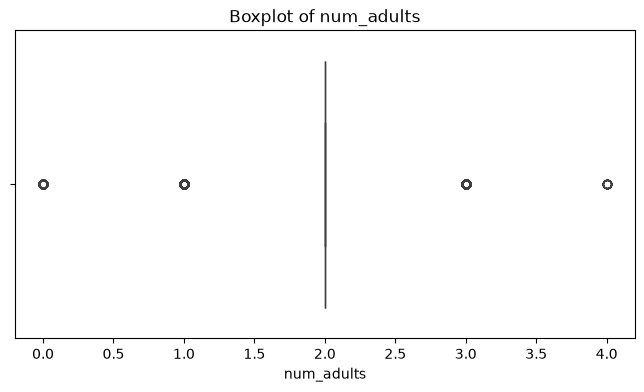

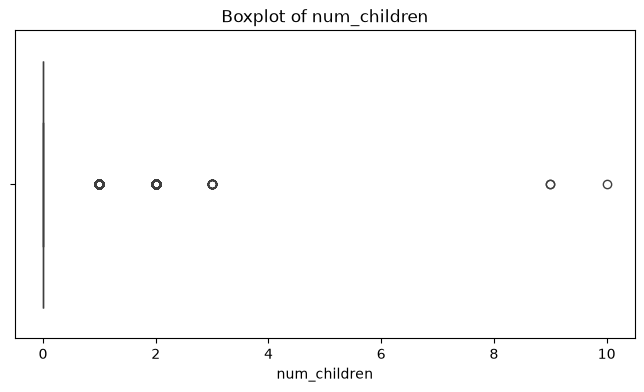

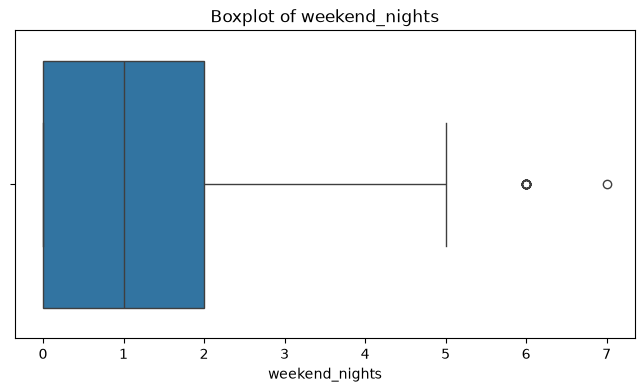

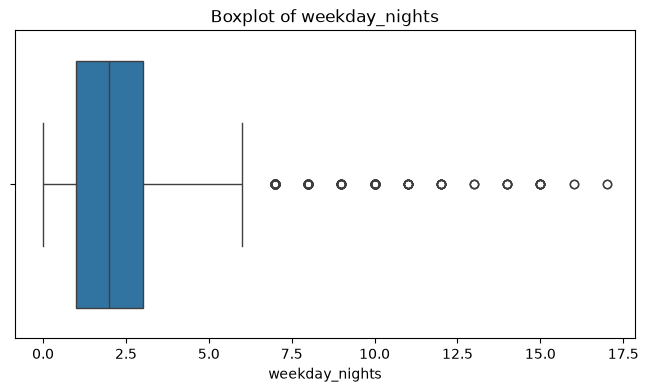

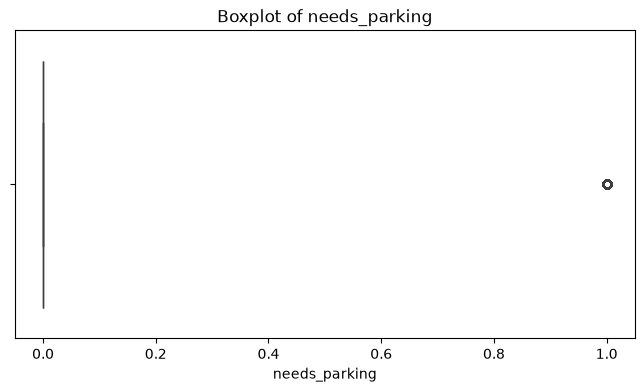

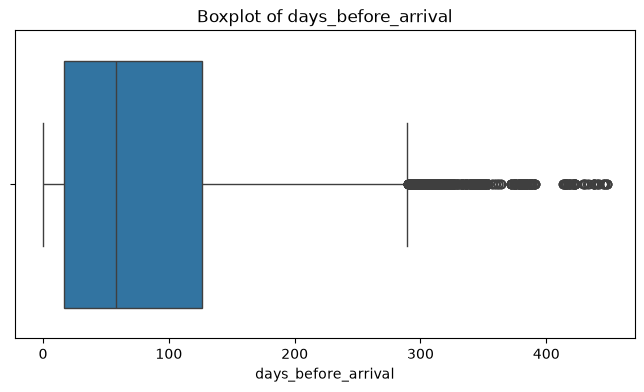

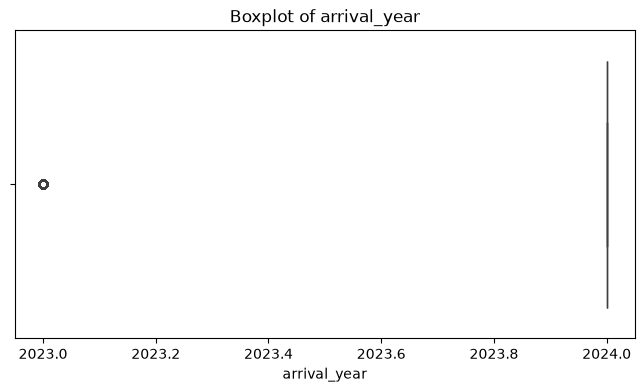

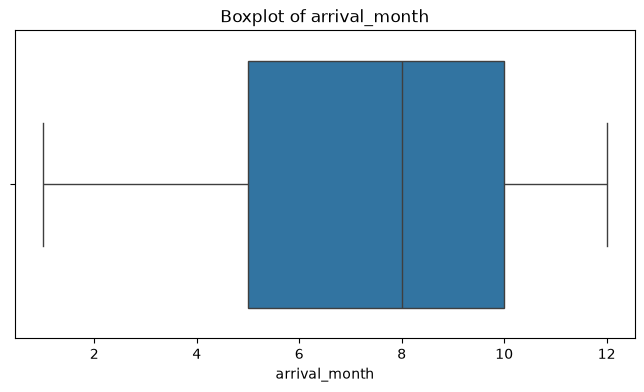

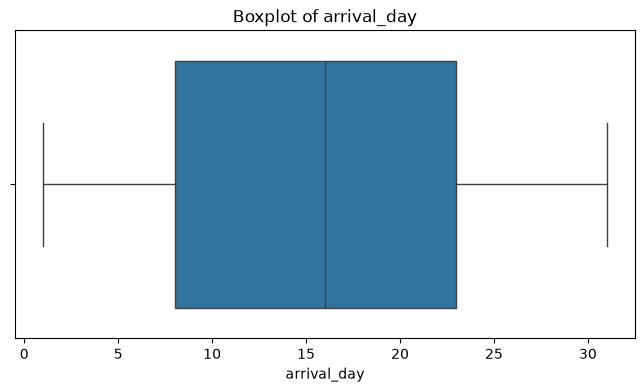

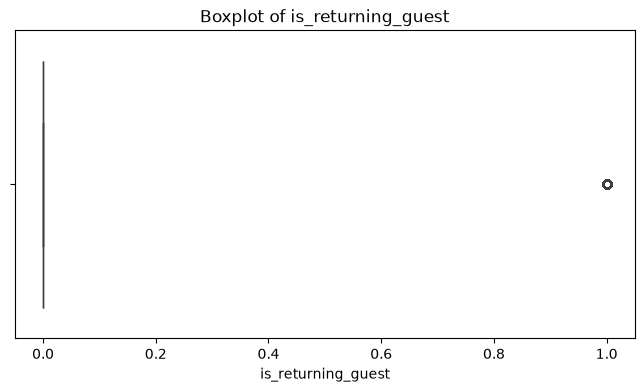

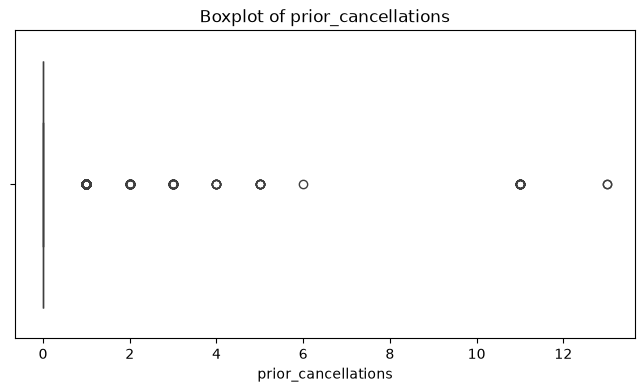

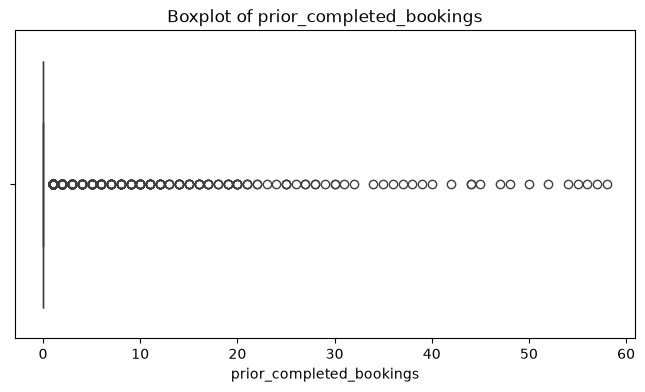

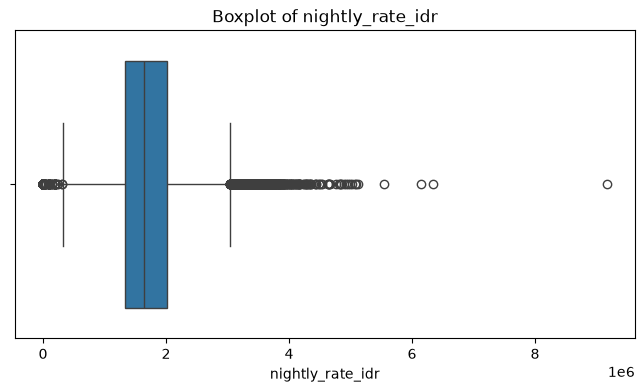

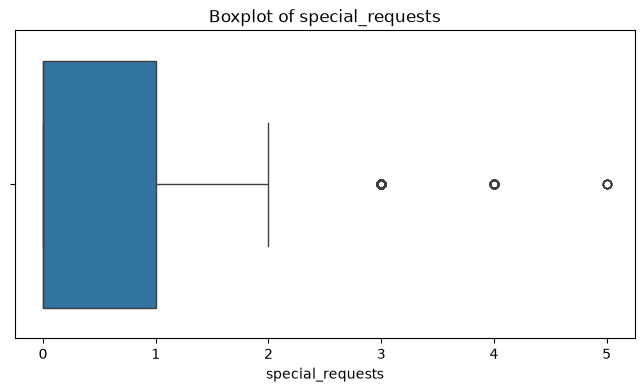

In [11]:
# Outlier 
for feature in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)
    plt.show()

#### Insight
- Outlier paling banyak ada di `nightly_rate_idr` dan `days_before_arrival`. Nilainya masih masuk akal, jadi tidak dihapus.
- Pada fitur diskret seperti `num_adults` dan `num_children`, banyak nilai ditandai outlier hanya karena datanya didominasi satu nilai, bukan karena datanya salah.

### 6. Fitur kategorikal

In [12]:
categorical_features = train_df.select_dtypes(include=['object']).columns.tolist()
categorical_features = [col for col in categorical_features if col not in unused_features]
print(f"Categorical features: {categorical_features}")

Categorical features: ['meal_package', 'room_category', 'booking_channel']


/tmp/ipykernel_1319224/2613818352.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train_df.select_dtypes(include=['object']).columns.tolist()


In [13]:
# Hitung jumlah booking dan tingkat pembatalan per kategori.
for feature in categorical_features:
    value_counts = train_df[feature].value_counts()
    cancel_rate = train_df.groupby(feature)['is_canceled'].mean()
    print(f"\nFeature: {feature}")
    print("Value Counts:")
    print(value_counts)
    print("Cancel Rate:")
    print(cancel_rate)


Feature: meal_package
Value Counts:
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
Full Board        4
Name: count, dtype: int64
Cancel Rate:
meal_package
Breakfast     0.311438
Full Board    0.250000
Half Board    0.459411
Room Only     0.338002
Name: is_canceled, dtype: float64

Feature: room_category
Value Counts:
room_category
Type B    20447
Type G     4396
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64
Cancel Rate:
room_category
Type A    0.426323
Type B    0.321416
Type C    0.248677
Type D    0.328794
Type E    0.285714
Type F    0.243697
Type G    0.341902
Name: is_canceled, dtype: float64

Feature: booking_channel
Value Counts:
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64
Cancel Rate:
booking_channel
Airline                0.306818
Complimentary       

In [14]:
for feature in categorical_features:
    rare_categories = train_df[feature].value_counts()[train_df[feature].value_counts() < 10].index.tolist()
    if rare_categories:
        print(f"\nFeature: {feature} has rare categories: {rare_categories}")



Feature: meal_package has rare categories: ['Full Board']

Feature: room_category has rare categories: ['Type E']


In [15]:
for feature in categorical_features:
    train_categories = set(train_df[feature].unique())
    test_categories = set(test_df[feature].unique())
    unseen_categories = test_categories - train_categories
    if unseen_categories:
        print(f"\nFeature: {feature} has unseen categories in test data: {unseen_categories}")

#### Insight
- `booking_channel` paling membedakan pembatalan. Online Travel Agent paling sering batal (36%), Corporate jarang (12%), dan Complimentary tidak pernah batal.
- Pada `meal_package`, Half Board paling sering batal (46%). Pada `room_category`, Type A paling sering batal (43%).
- Full Board dan Type E muncul kurang dari 10 kali, jadi cancel rate keduanya belum bisa dijadikan pegangan.

### 7. Hubungan antarfitur

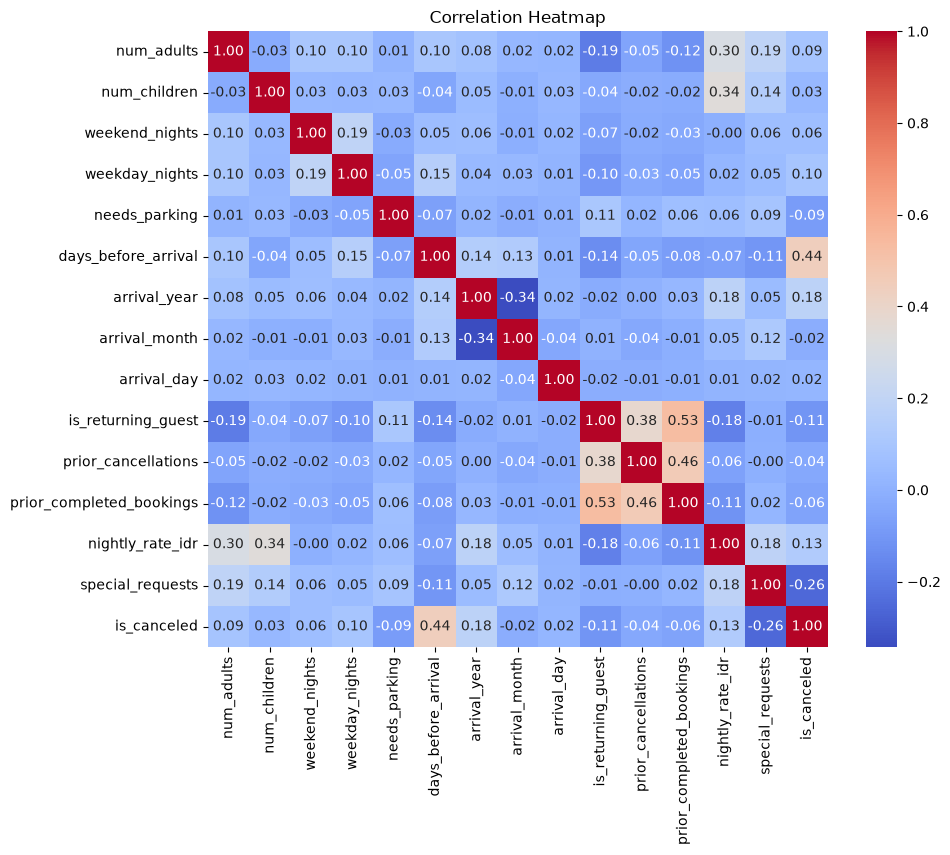

In [16]:
#Heatmap korelasi untuk fitur numerik dan target
numeric_features_with_target = numeric_features + ['is_canceled']
plt.figure(figsize=(10, 8))
sns.heatmap(train_df[numeric_features_with_target].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#### Insight
- `days_before_arrival` paling berkorelasi dengan pembatalan (0,44). Makin jauh hari booking dibuat, makin besar peluangnya dibatalkan.
- `special_requests` berkorelasi negatif (−0,26). Tamu yang punya permintaan khusus lebih jarang membatalkan.

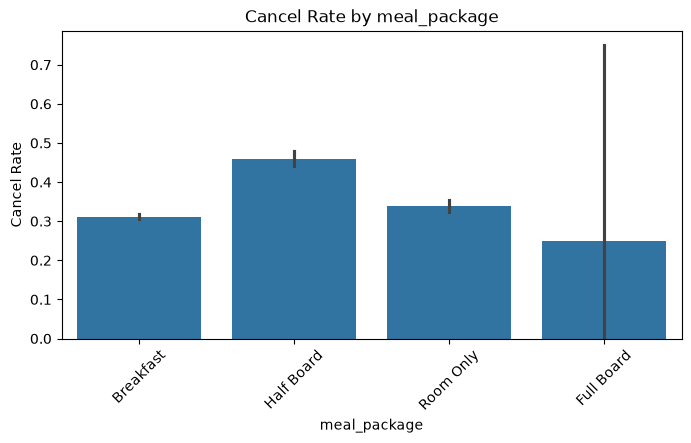

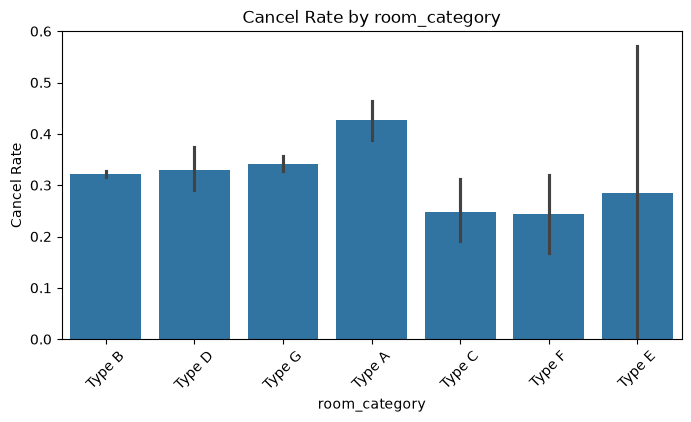

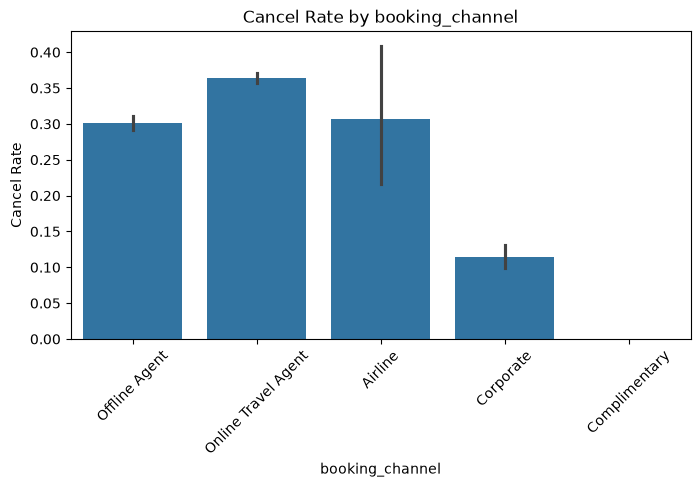

In [17]:
# Hubungan antara fitur kategorikal dan target
for feature in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=feature, y='is_canceled', data=train_df)
    plt.title(f'Cancel Rate by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Cancel Rate')
    plt.xticks(rotation=45)
    plt.show()

#### Insight
- Grafik ini sejalan dengan tabel sebelumnya. Perbedaan paling besar ada di `booking_channel`, sedangkan perbedaan antarkategori `room_category` lebih kecil.

In [18]:
# Uji chi-square untuk tiap fitur kategorikal terhadap target.
categorical_features_with_target = categorical_features + ['is_canceled']
for feature in categorical_features:
    contingency_table = pd.crosstab(train_df[feature], train_df['is_canceled'])
    chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-square test for feature: {feature}")
    print(f"Chi-square Statistic: {chi2_stat:.4f}, p-value: {p_value:.4f}, Degrees of Freedom: {dof}")
    


Chi-square test for feature: meal_package
Chi-square Statistic: 201.8292, p-value: 0.0000, Degrees of Freedom: 3

Chi-square test for feature: room_category
Chi-square Statistic: 47.7565, p-value: 0.0000, Degrees of Freedom: 6

Chi-square test for feature: booking_channel
Chi-square Statistic: 585.1653, p-value: 0.0000, Degrees of Freedom: 4


#### Insight
- Ketiga fitur kategorikal berhubungan dengan pembatalan (p-value < 0,0001), jadi semuanya layak dipakai. Hubungan terkuat ada pada `booking_channel`.

In [19]:
# VIF memakai diagonal pseudoinvers matriks korelasi.
corr = train_df[numeric_features].corr()
vif = np.diag(np.linalg.pinv(corr))
print("\nVariance Inflation Factor (VIF) for Numeric Features:")
for i, feature in enumerate(numeric_features):
    print(f"{feature}: {vif[i]:.2f}")


Variance Inflation Factor (VIF) for Numeric Features:
num_adults: 1.21
num_children: 1.17
weekend_nights: 1.05
weekday_nights: 1.07
needs_parking: 1.03
days_before_arrival: 1.16
arrival_year: 1.27
arrival_month: 1.24
arrival_day: 1.00
is_returning_guest: 1.54
prior_cancellations: 1.32
prior_completed_bookings: 1.58
nightly_rate_idr: 1.39
special_requests: 1.12


#### Insight
- Semua nilai VIF di bawah 1,6, jauh dari batas umum 5. Tidak ada multikolinearitas yang berarti di antara fitur numerik, jadi semuanya bisa dipakai.

### 8. Pola waktu

In [20]:
# Pisahkan per tahun agar pola pembatalan bulanan bisa dibaca.
for year in train_df['arrival_year'].unique():
    for month in train_df['arrival_month'].unique():
        subset = train_df[(train_df['arrival_year'] == year) & (train_df['arrival_month'] == month)]
        if not subset.empty:
            cancel_rate = subset['is_canceled'].mean()
            print(f"Cancel rate for {year}-{month}: {cancel_rate:.2f}")

Cancel rate for 2024-4: 0.36
Cancel rate for 2024-8: 0.46
Cancel rate for 2024-9: 0.47
Cancel rate for 2024-6: 0.41
Cancel rate for 2024-11: 0.34
Cancel rate for 2024-12: 0.17
Cancel rate for 2024-2: 0.26
Cancel rate for 2024-5: 0.37
Cancel rate for 2024-7: 0.42
Cancel rate for 2024-10: 0.47
Cancel rate for 2024-3: 0.30
Cancel rate for 2024-1: 0.03
Cancel rate for 2023-8: 0.19
Cancel rate for 2023-9: 0.11
Cancel rate for 2023-11: 0.04
Cancel rate for 2023-12: 0.03
Cancel rate for 2023-7: 0.64
Cancel rate for 2023-10: 0.16


#### Insight
- Cancel rate berubah dari bulan ke bulan. Pada 2024, nilainya rendah di awal dan akhir tahun (3% di Januari, 17% di Desember) dan tinggi pada Agustus–Oktober (sekitar 47%).
- Data 2023 hanya mencakup Juli–Desember, jadi tidak bisa dibandingkan langsung dengan 2024.

## Pembagian data <a id="data-split"></a>

Semua perbandingan memakai satu split validasi dari `train.csv` yang dibagi per kelompok. Baris dengan nilai prediktor mentah yang identik selalu masuk ke sisi yang sama. Split ini dipakai untuk mengukur konfigurasi yang sudah dipilih saat pengembangan, bukan untuk mencari konfigurasi baru dan bukan pengganti skor Kaggle.

In [21]:
FEATURE_SEED = 20261123
TARGET = 'is_canceled'
train = train_df.set_index('id', verify_integrity=True)
X = train.drop(columns=TARGET)
y = train[TARGET].to_numpy()
X_test = test_df.set_index('id', verify_integrity=True)
if X.index.hasnans or X_test.index.hasnans or not X.index.intersection(X_test.index).empty:
    raise ValueError('ID train dan test harus terisi dan saling terpisah.')
if set(X_test.columns) != set(X.columns):
    raise ValueError('Kolom prediktor train dan test berbeda.')
X_test = X_test[X.columns]

groups = raw_groups(X)
train_idx, valid_idx = next(StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=FEATURE_SEED,
).split(X, y, groups))
assert set(groups[train_idx]).isdisjoint(groups[valid_idx])
X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
y_train, y_valid = y[train_idx], y[valid_idx]
display(pd.DataFrame([
    {'bagian': name, 'baris': len(idx), 'grup': len(np.unique(groups[idx])),
     'proporsi batal': y[idx].mean()}
    for name, idx in [('latih', train_idx), ('validasi', valid_idx)]
]).round(4))

/tmp/ipykernel_1319224/3372227572.py:3: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  train = train_df.set_index('id', verify_integrity=True)
/tmp/ipykernel_1319224/3372227572.py:6: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  X_test = test_df.set_index('id', verify_integrity=True)


,bagian,baris,grup,proporsi batal
0,latih,21898,21846,0.3286
1,validasi,5475,5461,0.3238


## Prapemrosesan dan rekayasa fitur <a id="preprocessing"></a>

Konfigurasi submisi di bawah berasal dari eksperimen saat pengembangan. Sebisa mungkin, setiap variasi dibandingkan dengan input dan split yang sama. Ukuran data latihnya tetap: C4.5 membagi seluruh data berlabel menjadi bagian *grow* dan *prune*, SVM memakai 16.000 baris, dan tiga model lain memakai 8.000 baris yang diambil secara terstratifikasi. Ukuran yang sama dipakai saat melatih model untuk validasi.

### Kelompok fitur yang digunakan

- **Kalender dan perilaku:** siklus hari, minggu, dan bulan, musim, log waktu tunggu, serta penanda permintaan khusus.
- **Rombongan, tarif, dan riwayat:** total tamu dan malam, log dan rasio tarif, serta proporsi pembatalan sebelumnya. Imputasi dilengkapi dengan penanda nilai kosong.
- **Target encoding dan tetangga:** tingkat pembatalan per kategori dan per tetangga, serta jarak ke tiap kelas. Untuk baris latih, fitur ini dihitung dari fold lain (*out-of-fold*). Data validasi dan test hanya memakai data latih sebagai referensi.

Nama `knn` di daftar fitur merujuk ke ringkasan tetangga, bukan model KNN kedua. Semua statistik transformasi dihitung dari data latih. Untuk C4.5, fitur tambahan dihitung dari bagian *grow*, lalu diterapkan ke bagian *prune* dan ke data validasi atau test.

In [22]:
FEATURE_GROUPS = {
    'dtl': ('calendar', 'behavior'),
    'svm': ('calendar', 'behavior', 'knn'),
    'logreg': ('calendar', 'party', 'price', 'history', 'behavior', 'missing', 'te', 'knn'),
    'bayes': ('te', 'knn'),
    'knn': ('behavior',),
}
SVM_CAP, SVM_KERNEL_CAP, SHARED_CAP = 16_000, 1_000, 8_000
SVM_CUTOFF = -0.1875
SVM_WEIGHTS = {'days_before_arrival': 2.0, 'nightly_rate_idr': 2.0, 'special_requests': 1.5}
SVM_DISTANCE_FEATURES = {
    'knn__nearest_class0_d2', 'knn__nearest_class1_d2',
    'knn__class0_minus_class1_nearest_d2', 'knn__mean_d2_k15',
}


def sample_rows(labels, limit, seed):
    positions = np.arange(len(labels))
    if len(positions) <= limit:
        return positions
    picked, _ = train_test_split(positions, train_size=limit, stratify=labels, random_state=seed)
    return picked

### DTL: fitur pohon dan partisi pruning

Pohon bisa langsung menangani kategori teks dan nilai kosong. Tarif nol di luar kanal `Complimentary` dianggap kosong dan kategori langka digabung. Sebelum pelatihan, ditambahkan penanda nilai kosong serta ringkasan kalender, durasi, rombongan, dan tarif.

In [23]:
dtl_text_features = ['meal_package', 'room_category', 'booking_channel']


def dtl_fit_rare(raw):
    # kategori dengan kurang dari 10 baris, dipelajari dari data training saja
    return {col: raw[col].value_counts()[lambda counts: counts < 10].index.tolist() for col in dtl_text_features}


def dtl_preprocess(raw, rare):
    df = raw.copy()
    df[dtl_text_features] = df[dtl_text_features].astype(object)  # C4.5 mengenali kategorikal dari dtype object
    invalid_rate = (df['nightly_rate_idr'] == 0) & (df['booking_channel'] != 'Complimentary')
    df.loc[invalid_rate, 'nightly_rate_idr'] = np.nan
    df['num_children'] = df['num_children'].clip(upper=4)
    for col, categories in rare.items():
        df.loc[df[col].isin(categories), col] = 'Other'

    df['special_requests_missing'] = df['special_requests'].isna().astype(int)
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['month_index'] = (df['arrival_year'] - 2023) * 12 + df['arrival_month']
    arrival_date = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']), errors='coerce'
    )
    df['arrival_dayofweek'] = arrival_date.dt.dayofweek
    df['rate_per_person'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)
    return df



def prepare_dtl(raw, labels, query):
    rare = dtl_fit_rare(raw)
    features = dtl_preprocess(raw, rare)
    grow, prune = next(StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=SEED,
    ).split(features, labels, raw_groups(raw)))
    query_raw = pd.concat([raw.iloc[prune], query], ignore_index=True)
    names = FEATURE_GROUPS['dtl']
    reference = raw.iloc[grow]
    blocks = build_blocks(reference, labels[grow], query_raw, set(names), seed=SEED)

    def append(base, side):
        parts = [blocks[name][side].add_prefix(f'block_{name}_') for name in names]
        return pd.concat([base.reset_index(drop=True), *parts], axis=1)

    a = append(features.iloc[grow], 0)
    b = append(dtl_preprocess(query_raw, rare), 1)
    bundle = {
        'rare_categories': rare, 'feature_groups': names, 'seed': SEED,
        'reference_train': reference, 'reference_labels': labels[grow],
    }
    return a, b.iloc[:len(prune)], b.iloc[len(prune):], labels[grow], labels[prune], bundle


dtl_grow, dtl_prune, dtl_valid, dtl_y_grow, dtl_y_prune, _ = prepare_dtl(X_train, y_train, X_valid)
(dtl_final_grow, dtl_final_prune, dtl_test, dtl_final_y_grow,
 dtl_final_y_prune, dtl_bundle) = prepare_dtl(X, y, X_test)

dtl_numeric = [col for col in dtl_grow if col not in dtl_text_features]
dtl_sk_preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), dtl_numeric),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ]), dtl_text_features),
])
dtl_sk_grow = dtl_sk_preprocessor.fit_transform(dtl_grow)
dtl_sk_valid = dtl_sk_preprocessor.transform(dtl_valid)

/tmp/ipykernel_1319224/643012087.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['arrival_dayofweek'] = arrival_date.dt.dayofweek
/tmp/ipykernel_1319224/643012087.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['arrival_dayofweek'] = arrival_date.dt.dayofweek
/tmp/ipykernel_1319224/643012087.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['arrival_dayofweek'] = arrival_date.dt.dayofweek
/tmp/ipykernel_1319224/643012087.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['arrival_dayofweek'] = arrival_date.dt.dayofweek


### SVM: standardisasi, bobot, dan blok tambahan

Fitur numerik diimputasi dengan median lalu distandardisasi. Fitur kategorikal diimputasi dengan modus lalu di-*one-hot*. Tiga fitur diberi bobot lebih besar sebelum semua fitur digabung. Jarak kuadrat pada blok tetangga ditransformasi dengan log bertanda, dan semua kolom tambahan dikalikan 0,75. Eksperimen kernel memakai sampel kecil yang sama agar kebutuhan memori QP dan SMO tetap terkendali.

In [24]:
svm_numeric = X.select_dtypes(include='number').columns.tolist()
svm_categorical = [col for col in X if col not in svm_numeric]


def prepare_svm(raw, labels, query, limit):
    positions = sample_rows(labels, limit, SEED)
    reference, ref_y = raw.iloc[positions], labels[positions]
    preprocessor = ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
        ]), svm_numeric),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), svm_categorical),
    ])
    a = preprocessor.fit_transform(reference)
    b = preprocessor.transform(query)
    weights = {svm_numeric.index(name): weight for name, weight in SVM_WEIGHTS.items()}
    for position, weight in weights.items():
        a[:, position] *= weight
        b[:, position] *= weight
    names = FEATURE_GROUPS['svm']
    blocks = build_blocks(reference, ref_y, query, set(names), seed=SEED)

    def append(base, side):
        extra = pd.concat([blocks[group][side] for group in names], axis=1)
        cols = extra.columns.intersection(SVM_DISTANCE_FEATURES)
        distances = extra[cols].to_numpy(dtype=float)
        extra[cols] = np.sign(distances) * np.log1p(np.abs(distances))
        return np.column_stack((base, 0.75 * extra.to_numpy(dtype=float)))

    bundle = {
        'preprocessor': preprocessor, 'numeric_weights': weights, 'cutoff': SVM_CUTOFF,
        'feature_groups': names, 'reference_train': reference, 'reference_labels': ref_y,
        'seed': SEED,
    }
    return append(a, 0), append(b, 1), ref_y, a.shape[1], bundle


svm_X_train, svm_X_valid, svm_y_train, _, _ = prepare_svm(X_train, y_train, X_valid, SVM_KERNEL_CAP)
svm_train, svm_valid, svm_labels, svm_dim, _ = prepare_svm(X_train, y_train, X_valid, SVM_CAP)
svm_final_X, svm_test, svm_final_y, svm_final_dim, svm_bundle = prepare_svm(X, y, X_test, SVM_CAP)

### Representasi KNN, regresi logistik, dan Naive Bayes

Ketiga model memakai imputasi dan *one-hot* yang sama pada blok dasar, lalu masing-masing mendapat blok tambahan sesuai daftar di atas. Untuk perbandingan Naive Bayes kategorikal dan TAN, fitur kontinu juga dibagi ke dalam bin kuantil yang dihitung dari data latih yang sama.

In [25]:
def prepare_shared(raw, labels, query):
    positions = np.sort(sample_rows(labels, SHARED_CAP, FEATURE_SEED))
    reference, ref_y = raw.iloc[positions].copy(), labels[positions].copy()
    model_names = ('knn', 'logreg', 'bayes')
    needed = {group for model in model_names for group in FEATURE_GROUPS[model]}
    blocks = build_blocks(reference, ref_y, query, needed, seed=FEATURE_SEED)
    matrices = {}
    for name in model_names:
        names = ('base', *FEATURE_GROUPS[name])
        matrices[name] = tuple(pd.concat([
            blocks[group][side].add_prefix(f'{group}:') for group in names
        ], axis=1) for side in (0, 1))
    return matrices, reference, ref_y


shared_valid, shared_reference, shared_y = prepare_shared(X_train, y_train, X_valid)
shared_test, shared_final_reference, shared_final_y = prepare_shared(X, y, X_test)


def shared_bundle(name, model):
    return {
        'model': model, 'feature_groups': FEATURE_GROUPS[name], 'seed': FEATURE_SEED,
        'reference_train': shared_final_reference, 'reference_labels': shared_final_y,
        'feature_columns': tuple(shared_test[name][0].columns),
    }

In [26]:
nb_text_features = ['meal_package', 'room_category', 'booking_channel']
nb_count_features = [
    'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking',
    'arrival_year', 'arrival_month', 'is_returning_guest', 'prior_cancellations', 'special_requests',
]
nb_continuous_features = ['days_before_arrival', 'nightly_rate_idr', 'prior_completed_bookings', 'arrival_day']


def nb_fit_preprocessing(raw, n_bins):
    # Semua yang dipelajari (kode teks, batas bin) hanya dari data training
    params = {'n_bins': n_bins, 'text_mapping': {}, 'bin_edges': {}}
    for col in nb_text_features:
        categories = sorted(raw[col].dropna().unique())
        params['text_mapping'][col] = {name: i for i, name in enumerate(categories)}
    quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
    for col in nb_continuous_features:
        params['bin_edges'][col] = np.unique(np.nanquantile(raw[col], quantiles))
    return params


def nb_transform(raw, params):
    columns = []
    for col in nb_text_features:
        # teks -> angka, kategori yang tidak pernah muncul di training jadi NaN (dilewati)
        columns.append(raw[col].map(params['text_mapping'][col]).to_numpy(dtype=float))
    for col in nb_count_features:
        columns.append(raw[col].to_numpy(dtype=float))
    for col in nb_continuous_features:
        values = raw[col].to_numpy(dtype=float)
        codes = np.digitize(values, params['bin_edges'][col]).astype(float)
        codes[np.isnan(values)] = np.nan
        columns.append(codes)
    return np.column_stack(columns)



NB_BINS, NB_ALPHA = 5, 2.0
nb_names = nb_text_features + nb_count_features + nb_continuous_features
nb_bin_params = nb_fit_preprocessing(shared_reference, NB_BINS)
nb_binned_train = np.nan_to_num(nb_transform(shared_reference, nb_bin_params), nan=-1)
nb_binned_valid = np.nan_to_num(nb_transform(X_valid, nb_bin_params), nan=-1)

# Kode rapat; kategori tak dikenal dipetakan ke modus data latih.
nb_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, dtype=np.int64)
nb_codes_train = nb_encoder.fit_transform(nb_binned_train)
nb_codes_valid = nb_encoder.transform(nb_binned_valid)
for column in range(nb_codes_train.shape[1]):
    mode = np.bincount(nb_codes_train[:, column]).argmax()
    nb_codes_valid[nb_codes_valid[:, column] == -1, column] = mode

### Protokol evaluasi

F1 makro memberi bobot yang sama untuk kelas batal dan tidak batal. Precision dan recall dihitung untuk kelas batal. ROC AUC dihitung dari probabilitas atau skor keputusan. Semua algoritma dievaluasi pada baris validasi yang sama. Jumlah data latih ikut dilaporkan karena tiap model dilatih dengan ukuran data yang berbeda.

In [27]:
def metrics(predictions, scores):
    return {
        'f1_makro': f1_score(y_valid, predictions, average='macro'),
        'akurasi': accuracy_score(y_valid, predictions),
        'precision': precision_score(y_valid, predictions, zero_division=0),
        'recall': recall_score(y_valid, predictions, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, scores),
    }


def model_result(model, features):
    probabilities = model.predict_proba(features)
    if isinstance(model, LogisticRegressionClassifier):
        # Implementasi ini memilih kelas positif tepat pada ambang 0,5.
        return model.classes_[(probabilities[:, 1] >= 0.5).astype(int)], probabilities[:, 1]
    return model.classes_[probabilities.argmax(axis=1)], probabilities[:, 1]


def cost_table(predictions, probabilities):
    fp_cost, fn_cost = 2, 1
    adjusted = predict_cost_sensitive(probabilities, fp_cost, fn_cost)
    threshold = cost_sensitive_threshold(fp_cost, fn_cost)
    return pd.DataFrame([
        {'keputusan': name, **classification_cost(y_valid, pred, fp_cost, fn_cost)}
        for name, pred in [('aturan model', predictions), (f'ambang {threshold:.3f}', adjusted)]
    ])


validation_results = []
validation_predictions = {}


def record_validation(name, configuration, n_train, predictions, scores):
    validation_results.append({
        'model': name, 'konfigurasi': configuration, 'baris latih': n_train,
        **metrics(predictions, scores),
    })
    validation_predictions[name] = predictions

## Decision Tree Learning (C4.5) <a id="c45"></a>

Reduced Error Pruning (REP) dievaluasi pada pohon yang sama, sebelum dan sesudah dipangkas, tanpa oversampling. Sebagai pembanding, model scikit-learn memakai `criterion='entropy'` dengan dua nilai `ccp_alpha`. Pembanding ini berbasis CART, jadi tidak identik dengan C4.5.

In [28]:
def dtl_result(model, features):
    rows = features[model.feature_names].to_numpy(dtype=object)
    probabilities = np.array([model.predict_distribution(model.root, row) for row in rows])
    return model.classes[probabilities.argmax(axis=1)], probabilities[:, 1]


dtl_model = C45DecisionTree().fit(dtl_grow, dtl_y_grow)
dtl_rows = [{'varian': 'C4.5 tanpa pruning', 'simpul': dtl_model.count_nodes(),
             **metrics(*dtl_result(dtl_model, dtl_valid))}]
dtl_model.prune(dtl_prune, dtl_y_prune)
dtl_predictions, dtl_scores = dtl_result(dtl_model, dtl_valid)
dtl_rows.append({'varian': 'C4.5 dengan REP', 'simpul': dtl_model.count_nodes(),
                 **metrics(dtl_predictions, dtl_scores)})
for alpha in (0.0, 0.0002):
    library = DecisionTreeClassifier(criterion='entropy', ccp_alpha=alpha, random_state=SEED)
    library.fit(dtl_sk_grow, dtl_y_grow)
    dtl_rows.append({'varian': f'scikit-learn, ccp_alpha={alpha:g}',
                     'simpul': library.tree_.node_count,
                     **metrics(*model_result(library, dtl_sk_valid))})
record_validation('C4.5', 'REP tanpa oversampling', len(dtl_grow), dtl_predictions, dtl_scores)
display(pd.DataFrame(dtl_rows).round(4))

,varian,simpul,f1_makro,akurasi,precision,recall,roc_auc
0,C4.5 tanpa pruning,24083,0.8113,0.8340,0.7395,0.7524,0.8278
1,C4.5 dengan REP,4281,0.8422,0.8641,0.8094,0.7592,0.8721
2,"scikit-learn, ccp_alpha=0",4069,0.8136,0.8367,0.7479,0.7479,0.8136
3,"scikit-learn, ccp_alpha=0.0002",2383,0.8217,0.8446,0.7646,0.7513,0.8469


### Model C4.5 untuk submisi

Model submisi memakai REP tanpa oversampling. Bagian *grow* dan *prune* diambil dari seluruh data berlabel. Model ini tidak dipakai untuk menghitung metrik validasi di atas.

In [29]:
dtl_submission = C45DecisionTree().fit(dtl_final_grow, dtl_final_y_grow)
dtl_submission.prune(dtl_final_prune, dtl_final_y_prune)
dtl_bundle.update(model=dtl_submission, candidate='+'.join(FEATURE_GROUPS['dtl']))

### Bonus: visualisasi pohon

Graf menampilkan paling banyak tiga cabang per simpul sampai kedalaman tiga. Pohon yang divisualisasikan adalah pohon hasil pruning dari perbandingan validasi.

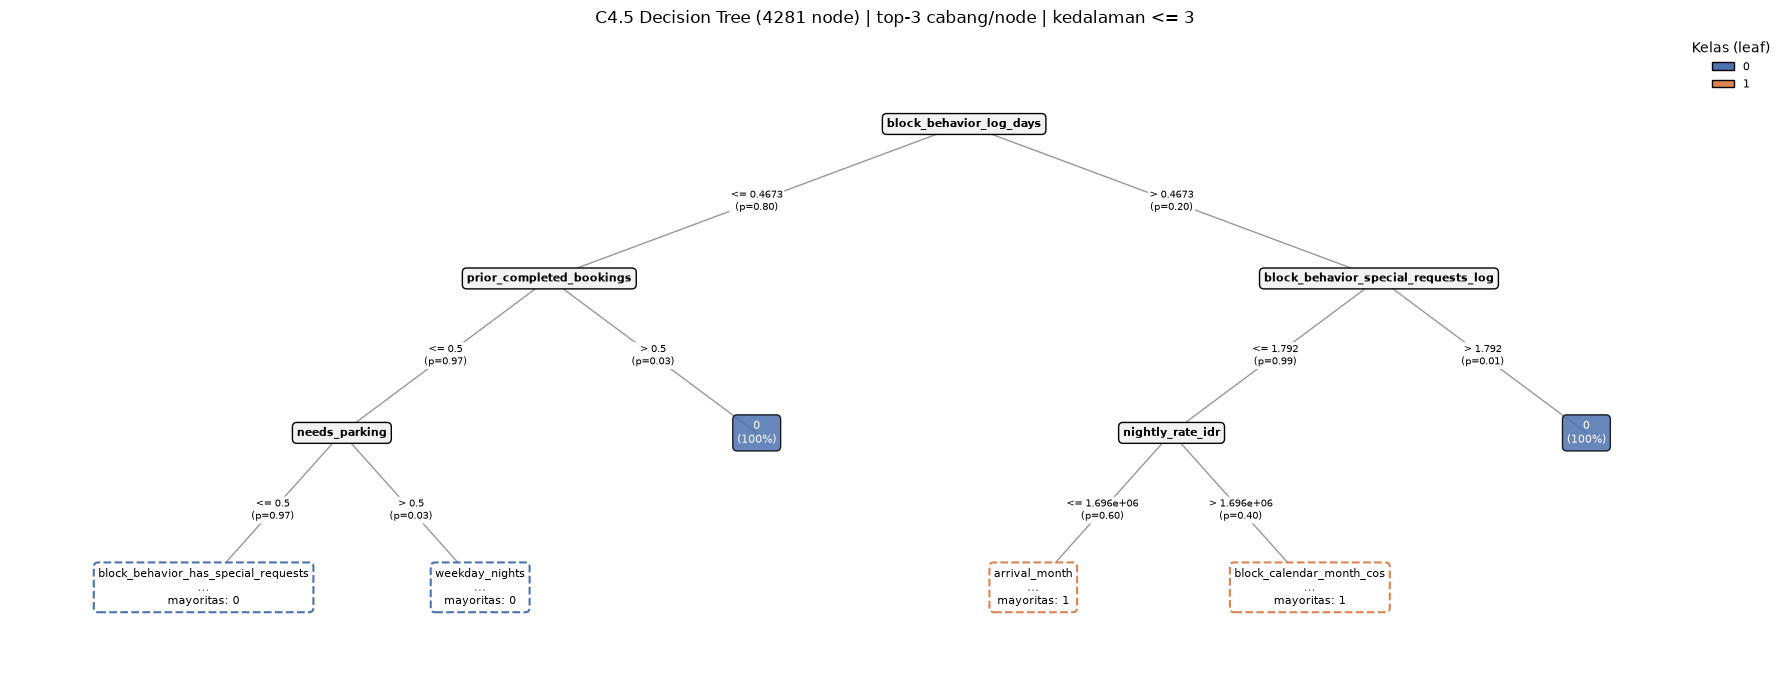

In [30]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
c45_plot_tree(dtl_model, top_n=3, max_depth=3, path=OUTPUT_DIR / 'c45_tree.png', figsize=(18, 7))
plt.show()

### Bonus: biaya kesalahan pada C4.5

Jika biaya false positive dua kali biaya false negative, ambang keputusan yang sesuai adalah 2/3. Ambang ini diuji pada estimasi peluang dari daun pohon. Bagian ini hanya simulasi biaya dan tidak mengubah aturan prediksi untuk submisi.

In [31]:
display(cost_table(dtl_predictions, dtl_scores))

,keputusan,false_positive,false_negative,total_cost
0,aturan model,317,427,1061.0
1,ambang 0.667,251,495,997.0


## Support Vector Machine (SVM) <a id="svm"></a>

Kernel linear, polinomial, dan Gaussian dibandingkan untuk QP, SMO, dan `SVC` pada 1.000 baris yang sama. Konfigurasi submisi (RBF dengan SMO) dievaluasi terpisah karena parameter dan jumlah datanya berbeda.

In [32]:
svm_kernel_configs = {kernel: {'kernel': kernel} for kernel in ('linear', 'poly', 'rbf')}
SVM_MAX_ITER = 50_000
svm_shared_params = {
    'C': 1.0, 'degree': 3, 'gamma': 1 / svm_X_train.shape[1], 'coef0': 1, 'tol': 1e-3,
}
svm_custom_models, svm_rows = {}, []


def svm_margin_scores(model, features):
    return np.concatenate([
        model.decision_function(features[start:start + 256])
        for start in range(0, len(features), 256)
    ])


for kernel, config in svm_kernel_configs.items():
    for solver in ('qp', 'smo', 'scikit-learn'):
        if solver == 'scikit-learn':
            model = SVC(**svm_shared_params, **config)
        else:
            model = SVM(**svm_shared_params, **config, solver=solver,
                        max_iter=SVM_MAX_ITER, random_state=SEED)
            svm_custom_models[solver, kernel] = model
        started = time.perf_counter()
        model.fit(svm_X_train, svm_y_train)
        seconds = time.perf_counter() - started
        scores = svm_margin_scores(model, svm_X_valid)
        svm_rows.append({
            'kernel': kernel, 'implementasi': solver, 'detik latih': seconds,
            'konvergen': model.fit_status_ == 0, **metrics(scores >= 0, scores),
        })
display(pd.DataFrame(svm_rows).round(4))

,kernel,implementasi,detik latih,konvergen,f1_makro,akurasi,precision,recall,roc_auc
0,linear,qp,12.9734,True,0.7923,0.8219,0.7442,0.6858,0.8803
1,linear,smo,1.7381,True,0.7920,0.8217,0.7440,0.6853,0.8803
2,linear,scikit-learn,0.0365,True,0.7920,0.8217,0.7440,0.6853,0.8803
3,poly,qp,12.1100,True,0.7852,0.8205,0.7662,0.6413,0.8724
4,poly,smo,0.5314,True,0.7849,0.8203,0.7660,0.6407,0.8724
5,poly,scikit-learn,0.0207,True,0.7849,0.8203,0.7660,0.6407,0.8724
6,rbf,qp,1.5646,True,0.7778,0.8164,0.7704,0.6170,0.8711
7,rbf,smo,0.2821,True,0.7776,0.8163,0.7703,0.6165,0.8711
8,rbf,scikit-learn,0.0236,True,0.7778,0.8164,0.7704,0.6170,0.8711


### Model SVM untuk submisi

Konfigurasi dari pengembangan memakai kernel RBF dengan SMO, `C=4`, `gamma=1.5 / jumlah_fitur_dasar`, dan ambang skor `-0.1875` pada 16.000 baris. Konfigurasi yang sama dilatih dua kali, sekali untuk validasi dan sekali untuk submisi, masing-masing dengan data latihnya sendiri.

In [33]:
def fit_rbf_smo(features, labels, base_dim):
    model = SVM(kernel='rbf', solver='smo', C=4.0, gamma=1.5 / base_dim,
                tol=1e-3, max_iter=SVM_MAX_ITER, random_state=SEED).fit(features, labels)
    if not model.converged_:
        raise RuntimeError('Konfigurasi RBF–SMO tidak konvergen.')
    return model


svm_model = fit_rbf_smo(svm_train, svm_labels, svm_dim)
svm_scores = svm_margin_scores(svm_model, svm_valid)
svm_predictions = (svm_scores >= SVM_CUTOFF).astype(int)
record_validation('SVM', 'RBF–SMO, C=4, ambang -0.1875', len(svm_train), svm_predictions, svm_scores)
display(pd.DataFrame([validation_results[-1]]).round(4))

svm_submission = fit_rbf_smo(svm_final_X, svm_final_y, svm_final_dim)
svm_bundle.update(model=svm_submission, candidate='+'.join(FEATURE_GROUPS['svm']))

,model,konfigurasi,baris latih,f1_makro,akurasi,precision,recall,roc_auc
0,SVM,"RBF–SMO, C=4, ambang -0.1875",16000,0.8615,0.8798,0.8262,0.7964,0.9248


### Bonus: batas keputusan pada dua komponen PCA

QP dan SMO dilatih pada proyeksi dua dimensi dari sampel eksperimen kernel. Daerah keputusan, margin, dan support vector ditampilkan untuk ketiga kernel. Model dua dimensi ini hanya untuk visualisasi.

/home/nicholaswisee/Code/projects/IF3170_G14_LalapKaoBole/src/models/svm/svm.py:237: RuntimeWarning: SVM optimization stopped before convergence
  warnings.warn("SVM optimization stopped before convergence", RuntimeWarning)


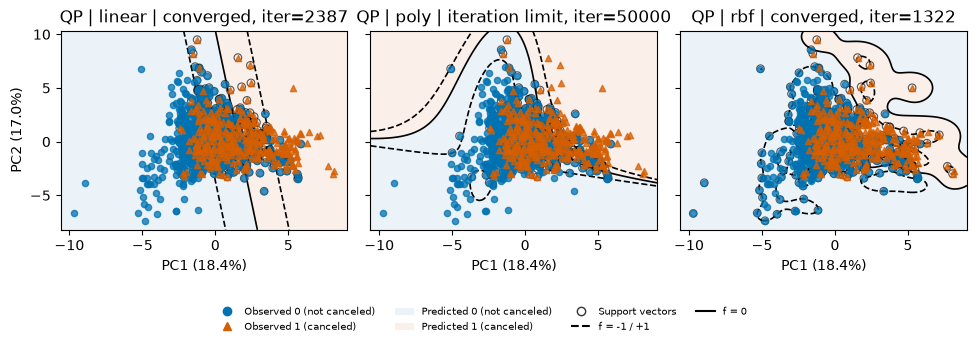

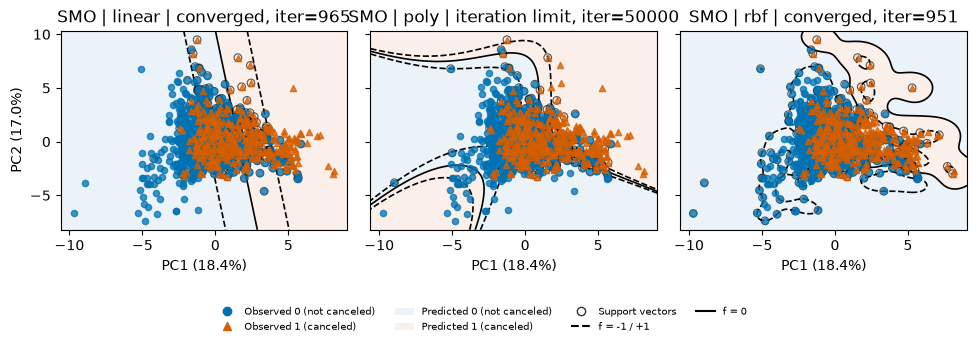

,solver,kernel,train_time,n_iter,converged,fit_status
0,qp,linear,5.968146,2387,True,0
1,qp,poly,65.098435,50000,False,1
2,qp,rbf,1.790064,1322,True,0
3,smo,linear,0.558800,965,True,0
4,smo,poly,17.464780,50000,False,1
5,smo,rbf,0.904013,951,True,0


In [34]:
svm_pca = PCA(n_components=2, random_state=SEED)
svm_X_train_2d = svm_pca.fit_transform(svm_X_train)
svm_visual_params = {**svm_shared_params, 'gamma': 1 / 2}
svm_visual_models = {}
svm_visual_results = []
svm_plot_lower = svm_X_train_2d.min(axis=0)
svm_plot_upper = svm_X_train_2d.max(axis=0)
svm_plot_padding = 0.05 * np.maximum(svm_plot_upper - svm_plot_lower, 1)
svm_plot_bounds = np.column_stack((svm_plot_lower - svm_plot_padding,
                                   svm_plot_upper + svm_plot_padding))
svm_boundary_axes = {}
for svm_solver in ('qp', 'smo'):
    svm_figure, svm_axes = plt.subplots(1, 3, figsize=(10, 3.5), sharex=True, sharey=True)
    svm_boundary_axes[svm_solver] = svm_axes
    for svm_index, (svm_ax, (svm_name, svm_config)) in enumerate(zip(svm_axes, svm_kernel_configs.items())):
        svm_visual_model = SVM(
            **svm_visual_params, **svm_config, solver=svm_solver,
            max_iter=SVM_MAX_ITER, random_state=SEED,
        )
        svm_start = time.perf_counter()
        svm_visual_model.fit(svm_X_train_2d, svm_y_train)
        svm_fit_seconds = time.perf_counter() - svm_start
        svm_visual_models[(svm_solver, svm_name)] = svm_visual_model
        svm_visual_results.append({
            'solver': svm_solver, 'kernel': svm_name,
            'train_time': svm_fit_seconds, 'n_iter': svm_visual_model.n_iter_,
            'converged': svm_visual_model.converged_,
            'fit_status': svm_visual_model.fit_status_,
        })
        svm_iteration_status = (
            'iteration limit' if not svm_visual_model.converged_
            and svm_visual_model.n_iter_ >= SVM_MAX_ITER else
            'converged' if svm_visual_model.converged_ else 'stopped early'
        )
        plot_svm_boundary(
            svm_visual_model, svm_X_train_2d, svm_y_train, ax=svm_ax,
            bounds=svm_plot_bounds, show_regions=True, legend=False, compact=True,
            title=f'{svm_solver.upper()} | {svm_name} | {svm_iteration_status}, iter={svm_visual_model.n_iter_}',
        )
        svm_ax.set(
            xlabel=f'PC1 ({svm_pca.explained_variance_ratio_[0]:.1%})',
            ylabel=f'PC2 ({svm_pca.explained_variance_ratio_[1]:.1%})' if svm_index == 0 else '',
        )
    svm_legend_handles = [
        Line2D([], [], marker='o', linestyle='None', color='#0072B2', label='Observed 0 (not canceled)'),
        Line2D([], [], marker='^', linestyle='None', color='#D55E00', label='Observed 1 (canceled)'),
        Patch(facecolor='#DCEAF3', alpha=0.55, label='Predicted 0 (not canceled)'),
        Patch(facecolor='#F8E3DA', alpha=0.55, label='Predicted 1 (canceled)'),
        Line2D([], [], marker='o', linestyle='None', markerfacecolor='none', color='0.2', label='Support vectors'),
        Line2D([], [], color='black', linestyle='--', label='f = -1 / +1'),
        Line2D([], [], color='black', linestyle='-', label='f = 0'),
    ]
    svm_figure.legend(
        handles=svm_legend_handles, loc='lower center', bbox_to_anchor=(0.5, 0.01),
        ncol=4, fontsize='x-small', frameon=False,
    )
    svm_figure.tight_layout(rect=(0, 0.16, 1, 1))
    plt.show()
pd.DataFrame(svm_visual_results)

### Kurva precision–recall

Kurva membandingkan ketiga kernel SMO pada sampel eksperimen kernel. Titik pada kurva menandai keputusan dengan ambang skor nol. Bonus biaya tidak dihitung untuk SVM karena skor margin bukan probabilitas.

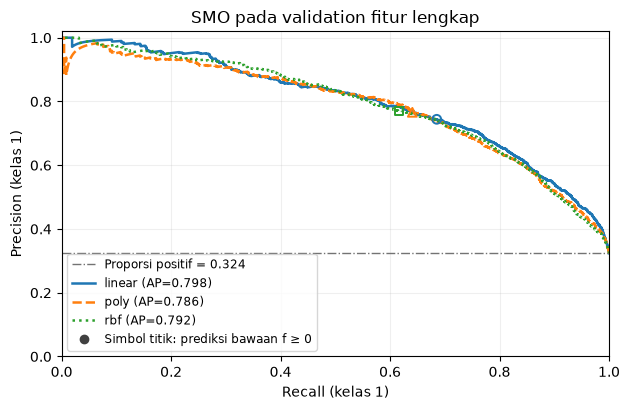

In [35]:
svm_pr_styles = {'linear': '-', 'poly': '--', 'rbf': ':'}
svm_pr_markers = {'linear': 'o', 'poly': '^', 'rbf': 's'}
svm_pr_figure, svm_pr_ax = plt.subplots(figsize=(6.4, 4.2))
svm_positive_prevalence = np.mean(np.asarray(y_valid) == 1)
svm_pr_ax.axhline(
    svm_positive_prevalence, color='0.45', linestyle='-.', linewidth=1,
    label=f'Proporsi positif = {svm_positive_prevalence:.3f}',
)
for svm_name in svm_kernel_configs:
    svm_pr_model = svm_custom_models[('smo', svm_name)]
    svm_pr_scores = svm_margin_scores(svm_pr_model, svm_X_valid)
    svm_pr_precision, svm_pr_recall, _ = precision_recall_curve(
        y_valid, svm_pr_scores, pos_label=1,
    )
    svm_pr_ap = average_precision_score(y_valid, svm_pr_scores, pos_label=1)
    svm_pr_line = svm_pr_ax.plot(
        svm_pr_recall, svm_pr_precision, linestyle=svm_pr_styles[svm_name],
        linewidth=1.8, label=f'{svm_name} (AP={svm_pr_ap:.3f})',
    )[0]
    svm_pr_predictions = (svm_pr_scores >= 0).astype(int)
    svm_pr_default_precision = precision_score(
        y_valid, svm_pr_predictions, pos_label=1, zero_division=0,
    )
    svm_pr_default_recall = recall_score(
        y_valid, svm_pr_predictions, pos_label=1, zero_division=0,
    )
    svm_pr_ax.scatter(
        svm_pr_default_recall, svm_pr_default_precision, s=40,
        marker=svm_pr_markers[svm_name], facecolors='none',
        edgecolors=svm_pr_line.get_color(), linewidths=1.4, zorder=4,
        label='_nolegend_',
    )
svm_pr_note = Line2D(
    [], [], marker='o', linestyle='None', color='0.25',
    label='Simbol titik: prediksi bawaan f ≥ 0',
)
svm_pr_ax.set(
    xlim=(0, 1), ylim=(0, 1.02), xlabel='Recall (kelas 1)',
    ylabel='Precision (kelas 1)', title='SMO pada validation fitur lengkap',
)
svm_pr_ax.grid(alpha=0.2)
svm_pr_ax.legend(handles=[*svm_pr_ax.get_lines(), svm_pr_note], fontsize='small')
svm_pr_figure.tight_layout()
plt.show()

## Logistic Regression <a id="logreg"></a>

Implementasi sendiri dan scikit-learn dibandingkan pada input yang sama untuk empat varian: tanpa penalti, L1, L2, dan Elastic Net. Submisi memakai L2 dengan kekuatan regularisasi 0,01.

In [36]:
LOGREG_PARAMS = {
    'learning_rate': 0.05, 'max_iter': 1_000, 'reg_strength': 0.01,
    'tol': 1e-3, 'random_state': FEATURE_SEED,
}
logreg_X_train, logreg_X_valid = (matrix.to_numpy(dtype=float) for matrix in shared_valid['logreg'])
logreg_custom_models, logreg_rows = {}, []
with threadpool_limits(limits=1, user_api='blas'):
    for variant, penalty in [('none', None), ('l1', 'l1'), ('l2', 'l2'), ('elasticnet', 'elasticnet')]:
        custom = LogisticRegressionClassifier(penalty=penalty, **LOGREG_PARAMS)
        library = LogisticRegression(
            penalty=penalty, C=1 / (len(shared_y) * LOGREG_PARAMS['reg_strength']),
            solver='saga', max_iter=LOGREG_PARAMS['max_iter'], tol=LOGREG_PARAMS['tol'],
            random_state=FEATURE_SEED, **({'l1_ratio': 0.5} if penalty == 'elasticnet' else {}),
        )
        logreg_custom_models[variant] = custom
        for name, model in [('buatan sendiri', custom), ('scikit-learn', library)]:
            started = time.perf_counter()
            model.fit(logreg_X_train, shared_y)
            seconds = time.perf_counter() - started
            pred, scores = model_result(model, logreg_X_valid)
            steps = int(np.asarray(model.n_iter_).reshape(-1)[0])
            converged = model.converged_ if model is custom else steps < LOGREG_PARAMS['max_iter']
            logreg_rows.append({
                'regularisasi': variant, 'implementasi': name, 'detik latih': seconds,
                'iterasi': steps, 'konvergen': converged, 'log_loss': log_loss(y_valid, scores),
                **metrics(pred, scores),
            })
            if model is custom and variant == 'l2':
                logreg_predictions, logreg_scores = pred, scores
record_validation('Regresi logistik', 'L2, lambda=0.01', len(shared_y), logreg_predictions, logreg_scores)
display(pd.DataFrame(logreg_rows).round(4))

/home/nicholaswisee/Code/projects/IF3170_G14_LalapKaoBole/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1232: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


,regularisasi,implementasi,detik latih,iterasi,konvergen,log_loss,f1_makro,akurasi,precision,recall,roc_auc
0,none,buatan sendiri,0.0664,54,True,0.4467,0.7667,0.8166,0.8289,0.5465,0.8745
1,none,scikit-learn,3.2850,565,True,0.4381,0.7683,0.8168,0.8214,0.5550,0.8756
2,l1,buatan sendiri,0.0413,42,True,0.4683,0.7640,0.8157,0.8351,0.5369,0.8731
3,l1,scikit-learn,4.0253,582,True,0.4507,0.7682,0.8164,0.8189,0.5561,0.8750
4,l2,buatan sendiri,0.0513,53,True,0.4482,0.7671,0.8172,0.8316,0.5460,0.8745
5,l2,scikit-learn,3.1683,556,True,0.4397,0.7676,0.8164,0.8221,0.5527,0.8755
6,elasticnet,buatan sendiri,0.0446,47,True,0.4582,0.7655,0.8166,0.8358,0.5398,0.8740
7,elasticnet,scikit-learn,3.8216,568,True,0.4449,0.7681,0.8163,0.8177,0.5567,0.8754


### Model regresi logistik untuk submisi

Konfigurasi L2 dilatih pada sampel submisi dari bagian prapemrosesan. Konfigurasi ini tetap dipakai walaupun ada varian lain yang skor validasinya lebih tinggi.

In [37]:
logreg_final_X, logreg_test = (matrix.to_numpy(dtype=float) for matrix in shared_test['logreg'])
logreg_submission = LogisticRegressionClassifier(penalty='l2', **LOGREG_PARAMS)
logreg_submission.fit(logreg_final_X, shared_final_y)
logreg_bundle = shared_bundle('logreg', logreg_submission)

/home/nicholaswisee/Code/projects/IF3170_G14_LalapKaoBole/src/models/logreg/logreg.py:157: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)


### Bonus: perbandingan pengoptimal

Hasil gradient ascent dari perbandingan regularisasi dipakai lagi di sini. Conjugate gradient dan L-BFGS dilatih pada input yang sama, untuk kasus tanpa penalti dan L2. Grafik menunjukkan loss pada data latih. Tabel juga mencantumkan status konvergensi dan kualitas prediksi.

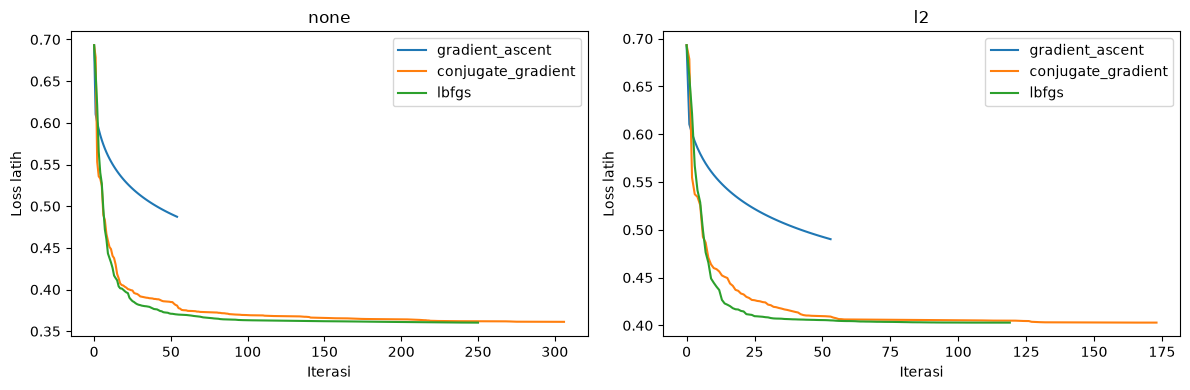

,regularisasi,pengoptimal,iterasi,konvergen,loss latih,log_loss validasi,f1_makro,akurasi,precision,recall,roc_auc
0,none,gradient_ascent,54,True,0.4873,0.4467,0.7667,0.8166,0.8289,0.5465,0.8745
1,none,conjugate_gradient,306,True,0.3613,0.3373,0.8303,0.8564,0.8174,0.7169,0.9166
2,none,lbfgs,250,True,0.3603,0.3373,0.8279,0.8544,0.8140,0.7135,0.9165
3,l2,gradient_ascent,53,True,0.4902,0.4482,0.7671,0.8172,0.8316,0.5460,0.8745
4,l2,conjugate_gradient,173,True,0.4029,0.3561,0.8156,0.8466,0.8197,0.6746,0.9117
5,l2,lbfgs,119,True,0.4029,0.3561,0.8161,0.8469,0.8204,0.6751,0.9116


In [38]:
logreg_optimizer_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
with threadpool_limits(limits=1, user_api='blas'):
    for ax, (variant, penalty) in zip(axes, [('none', None), ('l2', 'l2')]):
        for solver in ('gradient_ascent', 'conjugate_gradient', 'lbfgs'):
            if solver == 'gradient_ascent':
                model = logreg_custom_models[variant]
            else:
                model = LogisticRegressionClassifier(solver=solver, penalty=penalty, **LOGREG_PARAMS)
                model.fit(logreg_X_train, shared_y)
            pred, scores = model_result(model, logreg_X_valid)
            logreg_optimizer_rows.append({
                'regularisasi': variant, 'pengoptimal': solver, 'iterasi': model.n_iter_,
                'konvergen': model.converged_, 'loss latih': model.loss_history_[-1],
                'log_loss validasi': log_loss(y_valid, scores), **metrics(pred, scores),
            })
            ax.plot(model.loss_history_, label=solver)
        ax.set(xlabel='Iterasi', ylabel='Loss latih', title=variant)
        ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame(logreg_optimizer_rows).round(4))

### Bonus: video kontur log-loss

Model satu fitur dipakai untuk memperlihatkan lintasan bobot dan intersep pada bidang dua dimensi. Model ini hanya untuk demonstrasi dan tidak dipakai untuk submisi.

In [39]:
video_feature = 'base:base__days_before_arrival'
video_X = shared_valid['logreg'][0][[video_feature]].to_numpy(dtype=float)
video_model = LogisticRegressionClassifier(
    learning_rate=0.1, max_iter=300, penalty=None, batch_size=None,
    tol=1e-6, random_state=SEED, record_history=True,
).fit(video_X, shared_y)
video_path = save_logreg_training_video(
    video_model, video_X, shared_y, OUTPUT_DIR / 'logreg_training.mp4',
    feature_name='days_before_arrival (distandardisasi)', fps=20,
)
display(Video(str(video_path), embed=True))

### Bonus: biaya kesalahan pada regresi logistik

Biaya keputusan model L2 dibandingkan antara ambang biasa dan ambang 2/3. Ambang 2/3 hanya untuk ilustrasi dan tidak mengubah konfigurasi submisi.

In [40]:
display(cost_table(logreg_predictions, logreg_scores))

,keputusan,false_positive,false_negative,total_cost
0,aturan model,196,805,1197.0
1,ambang 0.667,26,1306,1358.0


## Naive Bayes <a id="naive-bayes"></a>

Dua nilai smoothing diuji pada representasi kategorikal dan campuran. Pada representasi kategorikal, Naive Bayes buatan sendiri dan `CategoricalNB` menerima kode yang sama. Pada representasi campuran, fitur biner diperlakukan sebagai kategorikal dan fitur lain dimodelkan dengan distribusi Gaussian. Representasi campuran ini memakai fitur `te` dan `knn` untuk submisi.

In [41]:
def nb_mixed_model(features, alpha):
    types = ['categorical' if len(np.unique(column)) <= 2 else 'gaussian' for column in features.T]
    return NaiveBayesClassifier(alpha=alpha, feature_types=types)


nb_train, nb_valid = (matrix.to_numpy(dtype=float) for matrix in shared_valid['bayes'])
nb_rows = []
for alpha in (1.0, NB_ALPHA):
    for name, model in (
        ('buatan sendiri', NaiveBayesClassifier(alpha=alpha, feature_types=['categorical'] * len(nb_names))),
        ('scikit-learn', CategoricalNB(alpha=alpha)),
    ):
        model.fit(nb_codes_train, shared_y)
        nb_rows.append({'representasi': f'{NB_BINS} bin', 'implementasi': name, 'alpha': alpha,
                        **metrics(*model_result(model, nb_codes_valid))})
    mixed = nb_mixed_model(nb_train, alpha).fit(nb_train, shared_y)
    pred, scores = model_result(mixed, nb_valid)
    nb_rows.append({'representasi': 'campuran', 'implementasi': 'buatan sendiri', 'alpha': alpha,
                    **metrics(pred, scores)})
    if alpha == NB_ALPHA:
        nb_predictions, nb_scores = pred, scores
record_validation('Naive Bayes', 'campuran, alpha=2', len(shared_y), nb_predictions, nb_scores)
display(pd.DataFrame(nb_rows).round(4))

,representasi,implementasi,alpha,f1_makro,akurasi,precision,recall,roc_auc
0,5 bin,buatan sendiri,1.0,0.7531,0.7903,0.6982,0.6210,0.8395
1,5 bin,scikit-learn,1.0,0.7531,0.7903,0.6982,0.6210,0.8395
2,campuran,buatan sendiri,1.0,0.6509,0.6513,0.4806,0.9521,0.8900
3,5 bin,buatan sendiri,2.0,0.7524,0.7900,0.6985,0.6182,0.8397
4,5 bin,scikit-learn,2.0,0.7524,0.7900,0.6985,0.6182,0.8397
5,campuran,buatan sendiri,2.0,0.6511,0.6515,0.4808,0.9521,0.8901


### Model Naive Bayes untuk submisi

Submisi memakai representasi campuran dengan `alpha=2`, hasil dari eksperimen saat pengembangan. Model dilatih pada sampel submisi tanpa membandingkan ulang kombinasi fitur.

In [42]:
nb_final_X, nb_test = (matrix.to_numpy(dtype=float) for matrix in shared_test['bayes'])
nb_submission = nb_mixed_model(nb_final_X, NB_ALPHA).fit(nb_final_X, shared_final_y)
nb_bundle = shared_bundle('bayes', nb_submission)

### Bonus: graf Naive Bayes dan Tree-Augmented Naive Bayes (TAN)

Graf Naive Bayes memperlihatkan hubungan tiap fitur dengan kelas. TAN menambahkan sisi antarfitur. Smoothing Laplace dan Dirichlet pada TAN dibandingkan dengan Naive Bayes kategorikal pada data latih dan validasi yang sama. TAN tidak dipakai untuk submisi.

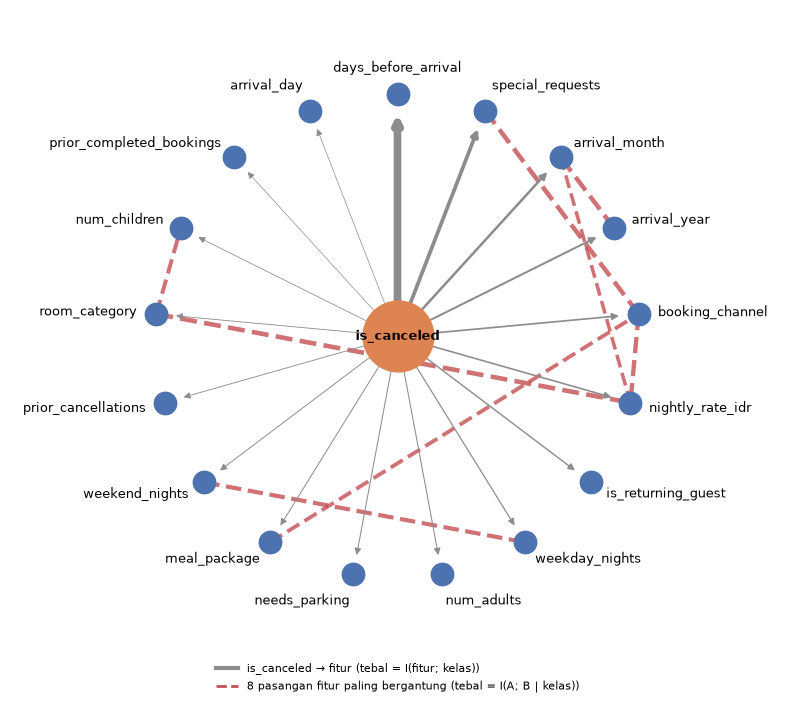

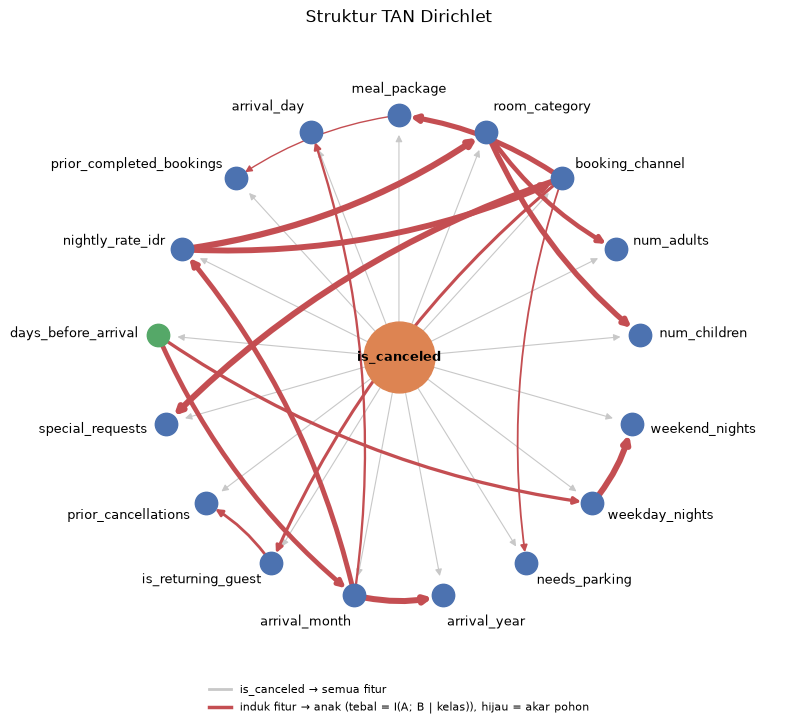

,representasi,implementasi,alpha,f1_makro,akurasi,precision,recall,roc_auc
0,5 bin,buatan sendiri,2.0,0.7524,0.7900,0.6985,0.6182,0.8397
1,5 bin,TAN laplace,2.0,0.7761,0.8117,0.7444,0.6373,0.8609
2,5 bin,TAN dirichlet,2.0,0.7727,0.8064,0.7235,0.6509,0.8575


In [43]:
fig, ax = plt.subplots(figsize=(10, 10))
plot_naive_bayes_graph(nb_codes_train, shared_y, nb_names, class_name='is_canceled', ax=ax)
plt.show()

tan_rows = [row for row in nb_rows if row['representasi'] == f'{NB_BINS} bin'
            and row['implementasi'] == 'buatan sendiri' and row['alpha'] == NB_ALPHA]
for smoothing in ('laplace', 'dirichlet'):
    tan = TreeAugmentedNaiveBayes(alpha=NB_ALPHA, smoothing=smoothing).fit(nb_codes_train, shared_y)
    tan_rows.append({'representasi': f'{NB_BINS} bin', 'implementasi': f'TAN {smoothing}',
                     'alpha': NB_ALPHA, **metrics(*model_result(tan, nb_codes_valid))})
    if smoothing == 'dirichlet':
        fig, ax = plt.subplots(figsize=(10, 10))
        plot_tan_structure(tan, nb_names, class_name='is_canceled', ax=ax, title='Struktur TAN Dirichlet')
        fig.savefig(OUTPUT_DIR / 'tan_structure.png', bbox_inches='tight')
        plt.show()
display(pd.DataFrame(tan_rows).round(4))

### Bonus: biaya kesalahan pada Naive Bayes

Aturan prediksi model campuran dibandingkan dengan ambang 2/3. Probabilitas Naive Bayes tidak dikalibrasi, jadi manfaat ambang ini hanya bisa dilihat dari total biaya pada data validasi.

In [44]:
display(cost_table(nb_predictions, nb_scores))

,keputusan,false_positive,false_negative,total_cost
0,aturan model,1823,85,3731.0
1,ambang 0.667,1632,100,3364.0


## K-Nearest Neighbors (KNN) <a id="knn"></a>

Dengan fitur yang sama, `k=7`, `k=15`, dan `k=31` dibandingkan dengan bobot jarak, ditambah bobot seragam untuk `k=15`. Implementasi sendiri dan scikit-learn diuji dengan variasi yang sama. Submisi memakai `k=15` dengan bobot jarak.

In [45]:
KNN_K, KNN_WEIGHTS = 15, 'distance'
knn_train, knn_valid = (matrix.to_numpy(dtype=float) for matrix in shared_valid['knn'])
knn_rows = []
for k, weights in [(7, KNN_WEIGHTS), (KNN_K, KNN_WEIGHTS), (31, KNN_WEIGHTS), (KNN_K, 'uniform')]:
    for name, estimator in [('buatan sendiri', KNNClassifier), ('scikit-learn', KNeighborsClassifier)]:
        model = estimator(n_neighbors=k, weights=weights).fit(knn_train, shared_y)
        pred, scores = model_result(model, knn_valid)
        knn_rows.append({'k': k, 'bobot': weights, 'implementasi': name, **metrics(pred, scores)})
        if estimator is KNNClassifier and (k, weights) == (KNN_K, KNN_WEIGHTS):
            knn_predictions, knn_scores = pred, scores
record_validation('KNN', 'k=15, bobot jarak', len(shared_y), knn_predictions, knn_scores)
display(pd.DataFrame(knn_rows).round(4))

,k,bobot,implementasi,f1_makro,akurasi,precision,recall,roc_auc
0,7,distance,buatan sendiri,0.8148,0.8407,0.7725,0.7202,0.8859
1,7,distance,scikit-learn,0.8148,0.8407,0.7725,0.7202,0.8859
2,15,distance,buatan sendiri,0.8192,0.8462,0.7933,0.7101,0.8986
3,15,distance,scikit-learn,0.8192,0.8462,0.7933,0.7101,0.8986
4,31,distance,buatan sendiri,0.8129,0.8426,0.7991,0.6864,0.9015
5,31,distance,scikit-learn,0.8129,0.8426,0.7991,0.6864,0.9015
6,15,uniform,buatan sendiri,0.7958,0.8283,0.7746,0.6627,0.8802
7,15,uniform,scikit-learn,0.7958,0.8283,0.7746,0.6627,0.8802


### Model KNN untuk submisi

Model menyimpan sampel submisi dan memakai bobot jarak. Fitur tambahan hanya dari blok perilaku. Kombinasi fitur dan ambang tidak dipilih berdasarkan hasil validasi.

In [46]:
knn_final_X, knn_test = (matrix.to_numpy(dtype=float) for matrix in shared_test['knn'])
knn_submission = KNNClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS).fit(knn_final_X, shared_final_y)
knn_bundle = shared_bundle('knn', knn_submission)

### Bonus: biaya kesalahan pada KNN

Keputusan dari voting berbobot jarak dibandingkan dengan ambang 2/3. Submisi tetap memakai aturan prediksi biasa.

In [47]:
display(cost_table(knn_predictions, knn_scores))

,keputusan,false_positive,false_negative,total_cost
0,aturan model,328,514,1170.0
1,ambang 0.667,143,791,1077.0


## Perbandingan antaralgoritma <a id="model-comparison"></a>

Tabel ini membandingkan model-model submisi pada split validasi yang sama. Kolom baris latih menunjukkan jumlah baris yang dipakai untuk membentuk model, dan C4.5 masih memakai bagian *prune* terpisah. Jumlah baris ini mengikuti konfigurasi tiap model, jadi perbandingannya tidak dilakukan pada jumlah data yang sama. Tidak ada pelatihan ulang atau pemilihan model di bagian ini.

,model,konfigurasi,baris latih,f1_makro,akurasi,precision,recall,roc_auc
0,C4.5,REP tanpa oversampling,17514,0.8422,0.8641,0.8094,0.7592,0.8721
1,SVM,"RBF–SMO, C=4, ambang -0.1875",16000,0.8615,0.8798,0.8262,0.7964,0.9248
2,Regresi logistik,"L2, lambda=0.01",8000,0.7671,0.8172,0.8316,0.5460,0.8745
3,Naive Bayes,"campuran, alpha=2",8000,0.6511,0.6515,0.4808,0.9521,0.8901
4,KNN,"k=15, bobot jarak",8000,0.8192,0.8462,0.7933,0.7101,0.8986


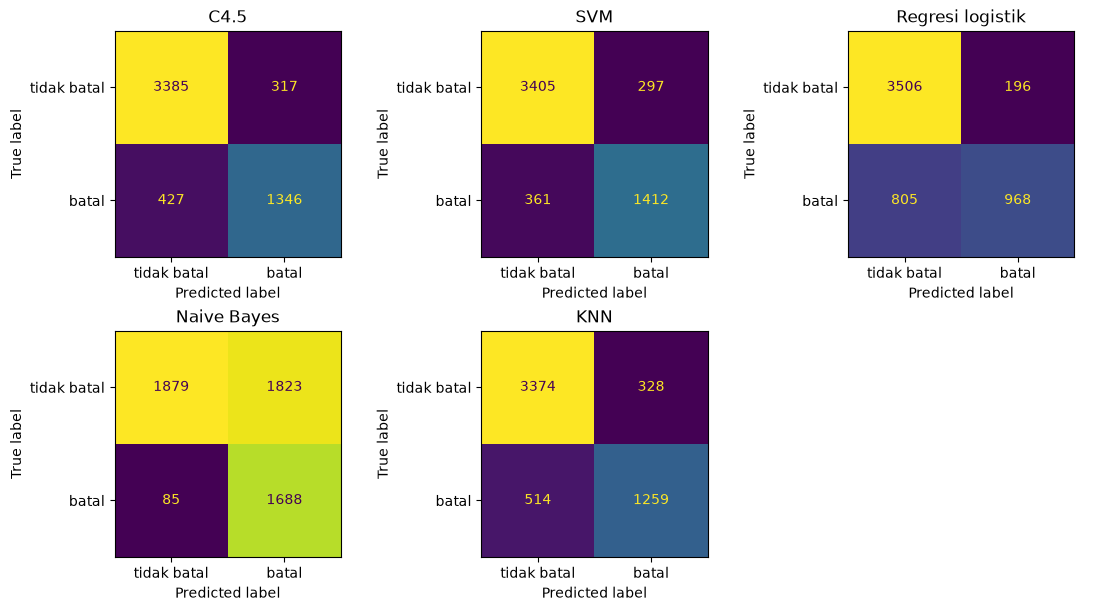

In [48]:
display(pd.DataFrame(validation_results).round(4))
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout='constrained')
for ax, (name, predictions) in zip(axes.flat, validation_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_valid, predictions, labels=[0, 1], display_labels=['tidak batal', 'batal'],
        colorbar=False, values_format='d', ax=ax,
    )
    ax.set_title(name)
axes.flat[-1].axis('off')
plt.show()

## Submisi <a id="submission"></a>

Submisi memakai model yang sudah dilatih di bagian masing-masing dan representasi test yang sudah disiapkan sebelumnya. Lima pasang file CSV dan PKL ditulis ke `output/`. Urutan baris CSV mengikuti `sample_submission.csv`. File PKL berisi model yang menghasilkan CSV tersebut, beserta konfigurasi dan referensi prapemrosesannya. Skor Kaggle dihitung di luar notebook.

In [49]:
template = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype={'id': str})
submission_ids = pd.Index(template['id'])
if submission_ids.hasnans or not submission_ids.is_unique or set(submission_ids) != set(X_test.index):
    raise ValueError('ID template harus terisi, unik, dan cocok dengan ID test.')

final_exports = {
    'dtl': (dtl_bundle, dtl_test),
    'svm': (svm_bundle, svm_test),
    'logreg': (logreg_bundle, logreg_test),
    'bayes': (nb_bundle, nb_test),
    'knn': (knn_bundle, knn_test),
}
final_submissions = {}
for name, (bundle, features) in final_exports.items():
    model = bundle['model']
    if name == 'svm':
        labels = svm_margin_scores(model, features) >= bundle['cutoff']
    else:
        labels = model.predict(features)
    if np.shape(labels) != (len(X_test),) or not np.isin(labels, (0, 1)).all():
        raise ValueError(f'Prediksi {name} harus berupa satu label biner per ID test.')
    aligned = pd.Series(labels, index=X_test.index).reindex(submission_ids)
    final_submissions[name] = pd.DataFrame({'id': submission_ids, TARGET: aligned.to_numpy(dtype=int)})

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Siapkan semua berkas sebelum mengganti keluaran dari run sebelumnya.
with TemporaryDirectory(dir=OUTPUT_DIR) as staging:
    staging_path = Path(staging)
    for name, submission in final_submissions.items():
        submission.to_csv(staging_path / f'submission_{name}.csv', index=False)
        bundle = {**final_exports[name][0], 'sklearn_version': sklearn_version}
        with (staging_path / f'{name}.pkl').open('wb') as stream:
            pickle.dump(bundle, stream, protocol=pickle.HIGHEST_PROTOCOL)
    for artifact in sorted(staging_path.iterdir()):
        artifact.replace(OUTPUT_DIR / artifact.name)

display(pd.DataFrame([
    {'berkas': f'submission_{name}.csv', 'baris': len(submission),
     'proporsi batal': submission[TARGET].mean()}
    for name, submission in final_submissions.items()
]).round(4))

,berkas,baris,proporsi batal
0,submission_dtl.csv,6844,0.3035
1,submission_svm.csv,6844,0.3139
2,submission_logreg.csv,6844,0.3025
3,submission_bayes.csv,6844,0.3309
4,submission_knn.csv,6844,0.2876
